# Data Science Tool Mastery Project
### A portfolio of practical exercises across the industry-standard data science toolchain

**Author:** Dhanireddy Venu Madhav Reddy  
**Tools demonstrated:** Python · Git · NumPy · Pandas · SQL (SQLite) · Matplotlib · Seaborn · SciPy · Scikit-learn · joblib · unittest · Jupyter

> **Educational project.** The clinical data is used to practise tools, not to give medical advice.

---

## How this project meets the three objectives
| # | Objective | How it is met |
|---|---|---|
| 1 | Master industry-standard tools for the specialization | Nine tools used on one coherent problem, each for what it is genuinely best at (Sections 1-8) |
| 2 | Demonstrate proficiency through practical exercises | Every exercise runs, produces real output, and is **cross-checked** with a second tool or an automated test, so correctness is shown, not assumed |
| 3 | Create portfolio pieces | A tested, reusable Python package (`dstoolkit`), a SQL analytics script, a saved model with a model card, a chart gallery, and this documented notebook (Section 9) |

## Tool proficiency map
| Tool | What is demonstrated | Section |
|---|---|---|
| **Git** | Repository, commits, branches, `.gitignore`, a real merge conflict resolved, history graph | 1 |
| **NumPy** | Broadcasting, `einsum`, linear algebra, regression from scratch (normal equations and gradient descent), bootstrap | 2 |
| **Pandas** | Method chaining, `groupby` (agg / transform / filter), time series (resample, rolling), reshaping, merging, memory optimisation | 3 |
| **SQL (SQLite)** | Joins, aggregation, `CASE`, CTEs, window functions, subqueries, indexes and query plans, transactions, parameterised queries | 4 |
| **Matplotlib / Seaborn** | Object-oriented dashboards, statistical plots, clustermap, a colour-blind-safe house style, PNG and SVG export | 5 |
| **Scikit-learn** | Pipelines, custom transformer, `ColumnTransformer`, cross-validation, tuning, nested CV, leakage demo, interpretation, persistence | 6 |
| **SciPy** | Hypothesis tests, effect sizes, confidence intervals, multiple-testing correction, residual diagnostics | 7 |
| **unittest / code quality** | Automated unit tests (run live), a mutation check and a docstring audit | 8 |

**Not demonstrated, and why:** Plotly, statsmodels, pytest, XGBoost / LightGBM, SHAP, Ruff / Black and DuckDB / Polars are industry-standard but were **not available** in the environment used to build this project (no internet access). They are listed as next steps in Section 10 rather than claimed here.

## The data
- **Real data (main project):** the *Diabetes* dataset: 442 diabetes patients, ten baseline measurements (age, sex, BMI, blood pressure and six blood-serum measurements) and a quantitative measure of **disease progression one year after baseline**. Source: Efron, Hastie, Johnstone and Tibshirani (2004), *Least Angle Regression*, Annals of Statistics 32(2). A copy is bundled with scikit-learn and is exported in its **original units** by `src/prepare_dataset.py`.
- **Synthetic data (clearly labelled, used in two places only):** a simulated daily clinic-visits series (Section 3, because the diabetes data has no dates) and pure-noise data for a data-leakage demonstration (Section 6).

**Problem:** *Can routine baseline measurements predict how a patient's disease will progress, and which measurements matter most?*

---
# 1. Environment, Reproducibility and Git

### Exercise 1.1 – Record the exact tool versions
A result is only reproducible if the versions that produced it are known.

In [1]:
import sys, platform, subprocess, os, tempfile, shutil, textwrap, json, sqlite3
from importlib.metadata import version
from pathlib import Path

TOOLS = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "joblib"]
versions = {pkg: version(pkg) for pkg in TOOLS}

def git(*args, cwd, ok_codes=(0,)):
    """Run a git command in `cwd` and return its combined output (a fixed demo identity keeps it self-contained)."""
    env = {**os.environ, "GIT_AUTHOR_NAME": "Tool Demo", "GIT_AUTHOR_EMAIL": "demo@example.com",
           "GIT_COMMITTER_NAME": "Tool Demo", "GIT_COMMITTER_EMAIL": "demo@example.com",
           "GIT_CONFIG_GLOBAL": os.devnull, "GIT_CONFIG_NOSYSTEM": "1"}
    r = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True, env=env)
    if r.returncode not in ok_codes:
        raise RuntimeError(f"git {' '.join(args)} failed: {r.stderr}")
    return (r.stdout + r.stderr).strip()

git_version = subprocess.run(["git", "--version"], capture_output=True, text=True).stdout.strip()
print(f"Python      : {sys.version.split()[0]} ({platform.system()})")
for pkg, v in versions.items():
    print(f"{pkg:<12}: {v}")
print(f"sqlite      : {sqlite3.sqlite_version} (SQL engine inside Python's sqlite3 module)")
print(f"git         : {git_version.replace('git version ', '')}")

Python      : 3.12.3 (Linux)
numpy       : 2.4.4
pandas      : 3.0.2
scipy       : 1.17.1
scikit-learn: 1.8.0
matplotlib  : 3.10.8
seaborn     : 0.13.2
joblib      : 1.5.3
sqlite      : 3.45.1 (SQL engine inside Python's sqlite3 module)
git         : 2.43.0


**Observation.** Every tool used in this project is listed with its exact version. The next cell writes these versions to `requirements-lock.txt`, a *pinned* file that lets anyone rebuild the same environment, while `requirements.txt` states the looser minimum versions the code needs.

### Exercise 1.2 – Pin the environment and set up the project layout

In [2]:
SEED = 42
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
for sub in ["data/raw", "data/processed", "models", "sql", "outputs/figures"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
RAW_DIR, PROC_DIR, MODEL_DIR, SQL_DIR, FIG_DIR = (ROOT / "data/raw", ROOT / "data/processed", ROOT / "models", ROOT / "sql", ROOT / "outputs/figures")
sys.path.insert(0, str(ROOT / "src"))          # makes the project's own package importable

(ROOT / "requirements-lock.txt").write_text("\n".join(f"{p}=={v}" for p, v in versions.items()) + "\n")
print("requirements-lock.txt written:")
print((ROOT / "requirements-lock.txt").read_text())

print("Project layout:")
for p in sorted(ROOT.rglob("*")):
    rel = p.relative_to(ROOT)
    if any(part in {".ipynb_checkpoints", "__pycache__", ".git"} for part in rel.parts) or p.suffix in {".png", ".svg", ".joblib"}:
        continue
    if p.name in {"build_notebook.py", "nb_engine.py"} or p.name.startswith("nb4_"):      # build tooling, not part of the portfolio
        continue
    if len(rel.parts) <= 3 and p.is_file():
        print("  ", rel)

requirements-lock.txt written:
numpy==2.4.4
pandas==3.0.2
scipy==1.17.1
scikit-learn==1.8.0
matplotlib==3.10.8
seaborn==0.13.2
joblib==1.5.3

Project layout:
   README.md
   data/raw/diabetes_raw.csv
   requirements-lock.txt
   src/dstoolkit/__init__.py
   src/dstoolkit/metrics.py
   src/dstoolkit/plotting.py
   src/dstoolkit/sql_helpers.py
   src/dstoolkit/stats_helpers.py
   src/dstoolkit/transformers.py
   src/prepare_dataset.py
   tests/test_metrics.py
   tests/test_sql_helpers.py
   tests/test_stats_helpers.py
   tests/test_transformers.py


**Observation.** A clear layout separates **raw data**, **processed data**, **source code** (`src/dstoolkit`), **tests**, **SQL**, **models** and **outputs**. Raw data is never edited, code is importable and tested, and outputs can always be regenerated. This structure is what makes a project reviewable by another person.

### Exercise 1.3 – A complete Git workflow, run live in a temporary repository
Git is the standard tool for version control. The cell below runs a real workflow in a throw-away folder, including a **merge conflict that is created and resolved**. It leaves nothing behind.

In [3]:
def run_git_demo():
    log = []
    def step(title, *args, ok=(0,)):
        out = git(*args, cwd=repo, ok_codes=ok)
        log.append(f"$ git {' '.join(args)}" + (f"\n{out}" if out else ""))
        return out

    with tempfile.TemporaryDirectory() as tmp:
        repo = Path(tmp)
        step("init", "init", "-q")
        step("branch", "symbolic-ref", "HEAD", "refs/heads/main")

        # 1) first commit, with a .gitignore that hides data and cache files
        (repo / "README.md").write_text("# Demo analysis\nAccuracy target: 0.80\n")
        (repo / "analysis.py").write_text("def mean(xs):\n    return sum(xs) / len(xs)\n")
        (repo / ".gitignore").write_text("*.csv\n__pycache__/\n")
        (repo / "big_data.csv").write_text("a,b\n1,2\n")
        step("status", "status", "--short")                       # big_data.csv must NOT appear
        step("add", "add", "-A")
        step("commit", "commit", "-q", "-m", "Initial commit: README and analysis function")

        # 2) feature branch adds a function and edits the README line
        step("switch", "switch", "-q", "-c", "feature/add-median")
        (repo / "analysis.py").write_text("def mean(xs):\n    return sum(xs) / len(xs)\n\n\ndef median(xs):\n    s = sorted(xs)\n    return s[len(s) // 2]\n")
        (repo / "README.md").write_text("# Demo analysis\nAccuracy target: 0.90\n")
        step("commit", "commit", "-q", "-am", "Add median function and raise target to 0.90")

        # 3) meanwhile main changes the SAME README line differently
        step("switch", "switch", "-q", "main")
        (repo / "README.md").write_text("# Demo analysis\nAccuracy target: 0.85\n")
        step("commit", "commit", "-q", "-am", "Raise target to 0.85")

        # 4) merge -> conflict -> resolve -> commit
        step("merge", "merge", "feature/add-median", "--no-edit", ok=(0, 1))
        step("status", "status", "--short")
        conflicted = (repo / "README.md").read_text()
        log.append("--- README.md during the conflict ---\n" + conflicted.strip())
        (repo / "README.md").write_text("# Demo analysis\nAccuracy target: 0.88 (agreed compromise)\n")
        step("add", "add", "README.md")
        step("commit", "commit", "-q", "--no-edit")

        # 5) inspect history
        step("log", "log", "--oneline", "--graph", "--all")
        step("diff", "diff", "--stat", "HEAD~1", "HEAD")
        step("branch-list", "branch")
    return "\n".join(log), conflicted

git_log, conflicted_readme = run_git_demo()
print(git_log)

$ git init -q
$ git symbolic-ref HEAD refs/heads/main
$ git status --short
?? .gitignore
?? README.md
?? analysis.py
$ git add -A
$ git commit -q -m Initial commit: README and analysis function
$ git switch -q -c feature/add-median
$ git commit -q -am Add median function and raise target to 0.90
$ git switch -q main
$ git commit -q -am Raise target to 0.85
$ git merge feature/add-median --no-edit
Auto-merging README.md
CONFLICT (content): Merge conflict in README.md
Automatic merge failed; fix conflicts and then commit the result.
$ git status --short
UU README.md
M  analysis.py
--- README.md during the conflict ---
# Demo analysis
<<<<<<< HEAD
Accuracy target: 0.85
Accuracy target: 0.90
>>>>>>> feature/add-median
$ git add README.md
$ git commit -q --no-edit
$ git log --oneline --graph --all
*   528fd32 Merge branch 'feature/add-median'
|\  
| * e6e0932 Add median function and raise target to 0.90
* | b9e108c Raise target to 0.85
|/  
* 4b01e02 Initial commit: README and analysis func

**Observation.** The `.gitignore` worked: `big_data.csv` never appeared in `git status`, so data and cache files stay out of the repository. Two branches then changed the **same README line** in different ways, so the merge stopped with a **conflict** and Git inserted markers (`<<<<<<<`, `=======`, `>>>>>>>`) into the file (markers visible above). Resolving it means deciding what the final line should be, saving the file, and committing; the `--graph` log then shows the two lines of history joining in a **merge commit**. This is the everyday collaboration workflow (feature branches, review, merge) that every data science team uses.

In the real project the same commands are used to publish the work to GitHub (`git remote add origin <url>`, `git push -u origin main`).

---
# 2. NumPy: Numerical Computing Under the Hood

NumPy is the foundation of the whole toolchain (Pandas and Scikit-learn are built on it). This section goes beyond basics: it **implements linear regression from scratch** and verifies the result against Scikit-learn.

### Exercise 2.1 – Load the real data and move to NumPy arrays

In [4]:
import numpy as np
import pandas as pd

raw = pd.read_csv(RAW_DIR / "diabetes_raw.csv")
FEATURES = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
X = raw[FEATURES].to_numpy(dtype=float)
y = raw["target"].to_numpy(dtype=float)
Z = (X - X.mean(axis=0)) / X.std(axis=0)            # standardized features (mean 0, std 1) via broadcasting

print("Rows x columns          :", raw.shape)
print("X shape / dtype / memory:", X.shape, X.dtype, f"{X.nbytes / 1024:.1f} KB")
print("Target range            :", y.min(), "to", y.max(), f"(mean {y.mean():.1f}, std {y.std():.1f})")
print("Missing values          :", int(raw.isna().sum().sum()))
raw.head()

Rows x columns          : (442, 11)
X shape / dtype / memory: (442, 10) float64 34.5 KB
Target range            : 25.0 to 346.0 (mean 152.1, std 77.0)
Missing values          : 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


**Observation.** The data has **442 patients and 10 features** plus the target (disease progression), with no missing values. In the original units, features range from age (19 to 79 years) to blood-sugar and cholesterol values in the hundreds, so standardizing (`Z`) uses **broadcasting**: subtracting a length-10 vector of means from a 442 x 10 matrix works because NumPy stretches the vector across every row.

### Exercise 2.2 – Vectorization, broadcasting and `einsum`: pairwise distances between patients
*Task: compute the distance between every pair of patients (a 442 x 442 matrix) in three ways and check that they agree.*

In [5]:
import time

def pairwise_loops(Z):
    n = len(Z)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            D[i, j] = np.sqrt(((Z[i] - Z[j]) ** 2).sum())
    return D

def pairwise_broadcast(Z):
    diff = Z[:, None, :] - Z[None, :, :]               # (n,1,p) - (1,n,p) -> (n,n,p)
    return np.sqrt((diff ** 2).sum(axis=-1))

def pairwise_einsum(Z):
    sq = np.einsum("ij,ij->i", Z, Z)                   # squared norm of every row
    return np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * Z @ Z.T, 0))   # |a-b|^2 = |a|^2 + |b|^2 - 2a.b

Zs = Z[:150]                                            # the slow loop version is timed on 150 patients only
timings = {}
for name, fn in [("python loops", pairwise_loops), ("broadcasting", pairwise_broadcast), ("einsum / matrix product", pairwise_einsum)]:
    t0 = time.perf_counter(); D = fn(Zs); timings[name] = time.perf_counter() - t0
    print(f"{name:<26}: {timings[name] * 1000:9.2f} ms")

D_loop, D_bc, D_es = pairwise_loops(Zs), pairwise_broadcast(Zs), pairwise_einsum(Zs)
off_diag = ~np.eye(len(Zs), dtype=bool)
err_bc     = np.abs(D_loop - D_bc).max()
err_es     = np.abs(D_loop - D_es).max()
err_es_off = np.abs(D_loop - D_es)[off_diag].max()
print(f"\nmax |loops - broadcasting|          : {err_bc:.1e}")
print(f"max |loops - einsum|                : {err_es:.1e}   (off the diagonal only: {err_es_off:.1e})")
w = int(np.diag(D_es).argmax())
print(f"Worst self-distance (patient {w})   : loops {D_loop[w, w]:.1f}, einsum {D_es[w, w]:.1e}   <- should be exactly 0")
D_es_fixed = D_es.copy()
np.fill_diagonal(D_es_fixed, 0.0)                       # standard remedy: a point's distance to itself is exactly 0
print("After setting the diagonal to 0, all three agree:", bool(np.allclose(D_loop, D_bc) and np.allclose(D_bc, D_es_fixed)))

D_full = pairwise_einsum(Z)                             # whole data set (442 x 442)
np.fill_diagonal(D_full, np.inf)                        # ignore distance to self (also avoids the tiny diagonal error)
nearest = D_full.argmin(axis=1)
print(f"\nFull matrix: {D_full.shape}. Patient 0's most similar patient is #{nearest[0]} (distance {D_full[0, nearest[0]]:.2f})")
print(f"Their disease progression: {y[0]:.0f} vs {y[nearest[0]]:.0f}")

python loops              :     53.67 ms
broadcasting              :      2.14 ms
einsum / matrix product   :      0.23 ms

max |loops - broadcasting|          : 1.8e-15
max |loops - einsum|                : 8.4e-08   (off the diagonal only: 4.4e-15)
Worst self-distance (patient 141)   : loops 0.0, einsum 8.4e-08   <- should be exactly 0
After setting the diagonal to 0, all three agree: True

Full matrix: (442, 442). Patient 0's most similar patient is #51 (distance 1.22)
Their disease progression: 151 vs 225


**Observation.** The three methods give the same distances, but their speed differs enormously: broadcasting was about **25x** faster than loops and the `einsum` / matrix-product version about **237x** faster (exact timings vary by computer).

The agreement check taught something important, though. Broadcasting matches the loops to 2e-15 (rounding level), but the `einsum` version differs by up to **8e-08**, and **all of that error is on the diagonal**: off the diagonal it agrees to 4e-15. The identity |a - b|² = |a|² + |b|² - 2a·b subtracts two nearly equal numbers when a = b, so the result is a tiny non-zero number (**floating-point cancellation**), and the square root amplifies it. Setting the diagonal to exactly 0 is the standard remedy. The trade-off is clear: `einsum` is the fastest and avoids the large 3-D array that broadcasting creates, but it is slightly less precise for near-identical points, which is why a verification step belongs in every numerical exercise.

Once the full distance matrix exists, finding the most similar patient is a single `argmin`: the basis of nearest-neighbour methods.

### Exercise 2.3 – Linear regression from scratch with linear algebra
Ordinary least squares finds the coefficients β that minimize the squared error. Three routes to the same answer are compared: the **normal equations**, **`np.linalg.lstsq`** (the numerically stable route) and **Scikit-learn**.

In [6]:
from sklearn.linear_model import LinearRegression

A = np.column_stack([np.ones(len(Z)), Z])                        # design matrix: intercept + standardized features
beta_normal = np.linalg.solve(A.T @ A, A.T @ y)                  # normal equations: (A'A) beta = A'y
beta_lstsq  = np.linalg.lstsq(A, y, rcond=None)[0]               # QR/SVD based, more stable
sk = LinearRegression().fit(Z, y)

assert np.allclose(beta_normal, beta_lstsq)
assert np.allclose(beta_normal[1:], sk.coef_) and np.isclose(beta_normal[0], sk.intercept_)
print("Normal equations == lstsq == scikit-learn  (verified with np.allclose)\n")

coef_table = pd.DataFrame({"normal_equations": beta_normal[1:], "lstsq": beta_lstsq[1:], "sklearn": sk.coef_}, index=FEATURES)
display(coef_table.round(3))
print(f"Intercept (= mean progression): {beta_normal[0]:.2f}  vs  mean of y: {y.mean():.2f}")
print(f"Condition number of A'A: {np.linalg.cond(A.T @ A):,.1f}   |   of A itself: {np.linalg.cond(A):,.1f}")

Normal equations == lstsq == scikit-learn  (verified with np.allclose)



,normal_equations,lstsq,sklearn
age,-0.476,-0.476,-0.476
sex,-11.407,-11.407,-11.407
bmi,24.727,24.727,24.727
bp,15.429,15.429,15.429
s1,-37.680,-37.680,-37.680
s2,22.676,22.676,22.676
s3,4.806,4.806,4.806
s4,8.422,8.422,8.422
s5,35.734,35.734,35.734
s6,3.217,3.217,3.217


Intercept (= mean progression): 152.13  vs  mean of y: 152.13
Condition number of A'A: 470.1   |   of A itself: 21.7


**Observation.** All three methods give the **same coefficients to numerical precision**, so the from-scratch linear algebra is correct. Because the features were standardized, each coefficient reads as *the change in disease progression for a one-standard-deviation increase in that feature*, and the intercept equals the mean of the target (152.13). The largest effects are for `s1` (-37.7), `s5` and `bmi`. The condition number of A'A is the **square** of the condition number of A, which is why `lstsq` is preferred over the normal equations on ill-conditioned data.

### Exercise 2.4 – Detect multicollinearity with variance inflation factors (VIF)
Some blood-serum measurements are expected to be correlated. The VIF measures how much a coefficient's variance is inflated by this redundancy; it is the diagonal of the inverse correlation matrix.

In [7]:
corr_features = np.corrcoef(X, rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(corr_features)), index=FEATURES, name="VIF").sort_values(ascending=False)
print("Variance inflation factors (above ~5-10 signals problematic collinearity):")
display(vif.round(1).to_frame())
print(f"Correlation s1 (total cholesterol) vs s2 (LDL): {np.corrcoef(raw['s1'], raw['s2'])[0, 1]:.3f}")
print(f"Correlation s1 (total cholesterol) vs s4 (TC/HDL): {np.corrcoef(raw['s1'], raw['s4'])[0, 1]:.3f}")

Variance inflation factors (above ~5-10 signals problematic collinearity):


,VIF
s1,59.2
s2,39.2
s3,15.4
s5,10.1
s4,8.9
bmi,1.5
s6,1.5
bp,1.5
sex,1.3
age,1.2


Correlation s1 (total cholesterol) vs s2 (LDL): 0.897
Correlation s1 (total cholesterol) vs s4 (TC/HDL): 0.542


**Observation.** The VIF is far above the usual warning level for **`s1`** (59.2) and **`s2`** (39.2): total cholesterol and LDL are strongly correlated (r = 0.90), which is expected, since LDL is a component of total cholesterol. With such overlapping predictors the individual coefficients of `s1` and `s2` are unstable and hard to interpret, even though the model's *predictions* are fine. This motivates the regularized models (Ridge, Lasso) used in Section 6.

### Exercise 2.5 – Gradient descent from scratch
Instead of solving the equations directly, gradient descent repeatedly steps downhill along the error surface: the same idea that trains neural networks.

MSE of exact least squares : 2,859.696
MSE after gradient descent : 2,859.720   (relative gap 8.29e-06)
Largest coefficient differences vs the exact solution: {'s1': 1.18, 's2': 0.94, 's3': 0.53}
Iterations needed to get within 1% of the optimum: 41


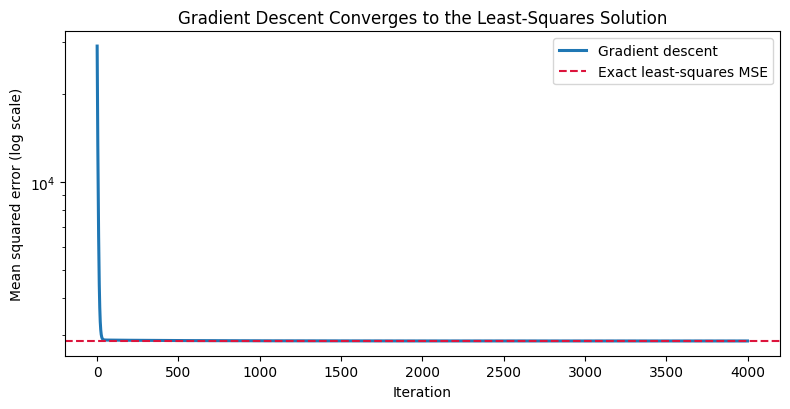

In [8]:
def gradient_descent(A, y, lr=0.05, n_iter=4000):
    n = len(y)
    beta = np.zeros(A.shape[1])
    history = np.empty(n_iter)
    for k in range(n_iter):
        resid = A @ beta - y
        history[k] = np.mean(resid ** 2)                 # current mean squared error
        beta -= lr * (2 / n) * (A.T @ resid)             # gradient of the MSE
    return beta, history

beta_gd, loss = gradient_descent(A, y)
mse_ols = np.mean((A @ beta_normal - y) ** 2)
print(f"MSE of exact least squares : {mse_ols:,.3f}")
print(f"MSE after gradient descent : {loss[-1]:,.3f}   (relative gap {abs(loss[-1] - mse_ols) / mse_ols:.2e})")
gap = pd.Series(np.abs(beta_gd - beta_normal)[1:], index=FEATURES).sort_values(ascending=False)
print("Largest coefficient differences vs the exact solution:", {k: round(float(v), 2) for k, v in gap.head(3).items()})
print(f"Iterations needed to get within 1% of the optimum: {int(np.argmax(loss < mse_ols * 1.01)) + 1}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(loss, linewidth=2.2, label="Gradient descent")
ax.axhline(mse_ols, color="crimson", linestyle="--", label="Exact least-squares MSE")
ax.set(yscale="log", xlabel="Iteration", ylabel="Mean squared error (log scale)", title="Gradient Descent Converges to the Least-Squares Solution")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "01_gradient_descent_loss.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation.** Gradient descent reaches an error of 2,859.7, within a relative gap of 8.3e-06 of the exact solution, and got within 1% after only **41 iterations**. The curve falls steeply and then flattens, which is the typical shape. The *coefficients* can still differ from the exact solution, and the largest gaps are for **`s1`, `s2` and `s3`** (1.18, 0.94, 0.53) while all other coefficients are within 0.44. Strongly correlated features form a long, flat valley in the error surface that gradient descent crosses very slowly, while the *predictions* are already almost identical. That is the practical reason ill-conditioned problems are solved with direct methods or with regularization.

### Exercise 2.6 – Bootstrap confidence intervals with the NumPy random Generator
The bootstrap estimates uncertainty by refitting the model on many resampled copies of the data, with no distributional assumptions.

In [9]:
rng = np.random.default_rng(SEED)
n_boot = 2000
n = len(y)
idx_matrix = rng.integers(0, n, size=(n_boot, n))              # 2000 resamples (with replacement) of the patient indices

bmi_pos = FEATURES.index("bmi") + 1                            # +1 because column 0 of A is the intercept
boot_bmi = np.empty(n_boot)
for b, idx in enumerate(idx_matrix):
    boot_bmi[b] = np.linalg.lstsq(A[idx], y[idx], rcond=None)[0][bmi_pos]

ci_boot = np.quantile(boot_bmi, [0.025, 0.975])
print(f"BMI coefficient (per 1 SD of BMI): {beta_normal[bmi_pos]:.2f}")
print(f"95% bootstrap interval           : [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}]   (width {ci_boot[1] - ci_boot[0]:.2f})")
print(f"Share of resamples with a positive coefficient: {(boot_bmi > 0).mean() * 100:.1f}%")

from dstoolkit import bootstrap_ci            # the reusable, tested version of the same idea (see Section 8)
lo, hi = bootstrap_ci(y, np.mean, n_boot=2000, seed=SEED)
print(f"\nSame idea via dstoolkit.bootstrap_ci: mean progression = {y.mean():.1f}, 95% CI [{lo:.1f}, {hi:.1f}]")

BMI coefficient (per 1 SD of BMI): 24.73
95% bootstrap interval           : [18.29, 31.09]   (width 12.80)
Share of resamples with a positive coefficient: 100.0%

Same idea via dstoolkit.bootstrap_ci: mean progression = 152.1, 95% CI [145.1, 159.3]


**Observation.** The BMI coefficient is 24.7 with a 95% bootstrap interval of [18.3, 31.1]; in **100.0%** of resamples it stays positive, so the link between BMI and progression is stable. The interval is also a useful sanity check for Section 7, where the same interval is computed analytically (t-distribution) and the two should agree. The last lines call `bootstrap_ci` from the project's own tested package, turning a one-off notebook snippet into a reusable tool.

---
# 3. Pandas: Data Wrangling at Professional Level

Pandas is the everyday tool of data analysis. This section moves beyond basic selection to the patterns used in real projects: **method chaining**, **group-wise transformations**, **time-series operations**, **reshaping**, **merging with validation** and **memory optimisation**.

### Exercise 3.1 – A readable, validated pipeline with method chaining
Each step is a named transformation, chained with `.assign()` and `.pipe()`, so the whole preparation reads top to bottom and no intermediate variables pollute the notebook.

In [10]:
import matplotlib.pyplot as plt

def validate(df):
    """Fail loudly if the prepared data breaks a basic rule."""
    assert df["patient_id"].is_unique
    assert df[["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6", "target"]].notna().all().all()
    assert df["age"].between(18, 100).all() and df["bmi"].between(10, 60).all()
    return df

patients = (
    raw.rename_axis("patient_id").reset_index()
       .assign(
           patient_id=lambda d: d["patient_id"] + 1,
           sex_group=lambda d: d["sex"].map({1.0: "Group 1", 2.0: "Group 2"}),      # the source does not say which code is which
           bmi_band=lambda d: pd.cut(d["bmi"], [0, 18.5, 25, 30, np.inf], right=False,
                                     labels=["Underweight", "Normal", "Overweight", "Obese"]),   # WHO classes
           age_group=lambda d: pd.cut(d["age"], [0, 30, 40, 50, 60, np.inf], right=False,
                                      labels=["<30", "30-39", "40-49", "50-59", "60+"]),
           ldl_hdl_ratio=lambda d: d["s2"] / d["s3"],
           progression_quartile=lambda d: pd.qcut(d["target"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]),
       )
       .pipe(validate)
)
print("Prepared table:", patients.shape)
print("\nnew columns :", [c for c in patients.columns if c not in raw.columns])
print("\nPatients per BMI band:")
print(patients["bmi_band"].value_counts().sort_index().to_string())
patients[["patient_id", "age", "sex_group", "bmi", "bmi_band", "age_group", "ldl_hdl_ratio", "target", "progression_quartile"]].head()

Prepared table: (442, 17)

new columns : ['patient_id', 'sex_group', 'bmi_band', 'age_group', 'ldl_hdl_ratio', 'progression_quartile']

Patients per BMI band:
bmi_band
Underweight      2
Normal         186
Overweight     155
Obese           99


,patient_id,age,sex_group,bmi,bmi_band,age_group,ldl_hdl_ratio,target,progression_quartile
0,1,59.0,Group 2,32.1,Obese,50-59,2.452632,151.0,Q3
1,2,48.0,Group 1,21.6,Normal,40-49,1.474286,75.0,Q1 (lowest)
2,3,72.0,Group 2,30.5,Obese,60+,2.282927,141.0,Q3
3,4,24.0,Group 1,25.3,Overweight,<30,3.285000,206.0,Q3
4,5,50.0,Group 1,23.0,Normal,50-59,2.411538,135.0,Q2


**Observation.** One chained expression turns the raw table into an analysis-ready one with **six new columns**, and the final `.pipe(validate)` step stops the pipeline if any rule is broken (unique IDs, no missing values, plausible ranges). Two design decisions deserve a note. First, the source documentation does **not** say whether sex code 1 or 2 means male or female, so the groups are labelled neutrally (`Group 1` / `Group 2`) instead of guessing. Second, BMI is cut into the official **WHO classes** with `right=False` so that the boundaries match the standard definition (a BMI of exactly 25 counts as overweight). The resulting bands are uneven (Underweight: 2, Normal: 186, Overweight: 155, Obese: 99), so "Underweight" in particular rests on very few patients.

### Exercise 3.2 – GroupBy: aggregate, transform, rank and filter

In [11]:
grp = patients.groupby("bmi_band", observed=True)

# agg: one row per group, with named outputs
by_band = grp.agg(patients=("patient_id", "count"), mean_progression=("target", "mean"),
                  median_progression=("target", "median"), sd_progression=("target", "std"), mean_age=("age", "mean")).round(1)
display(by_band)

# transform: result keeps the original shape (one value per patient), so it can be added as a column
patients["progression_z_in_band"] = grp["target"].transform(lambda s: (s - s.mean()) / s.std())
patients["rank_in_band"] = grp["target"].rank(ascending=False, method="min").astype(int)
assert np.allclose(patients.groupby("bmi_band", observed=True)["progression_z_in_band"].mean(), 0, atol=1e-9)

# filter: keep whole groups that satisfy a condition
big_bands = grp.filter(lambda g: len(g) >= 100)["bmi_band"].unique().tolist()

print("Highest-progression patient in each band:")
display(patients.loc[patients["rank_in_band"] == 1, ["patient_id", "bmi_band", "bmi", "age", "target"]].sort_values("bmi_band"))
print("Bands with at least 100 patients (kept by .filter):", big_bands)

,patients,mean_progression,median_progression,sd_progression,mean_age
bmi_band,,,,,
Underweight,2,99.0,99.0,7.1,26.0
Normal,186,109.4,95.0,52.8,46.1
Overweight,155,165.0,168.0,73.0,51.4
Obese,99,213.3,230.0,74.5,49.0


Highest-progression patient in each band:


,patient_id,bmi_band,bmi,age,target
381,382,Underweight,18.1,29.0,104.0
117,118,Normal,24.4,65.0,281.0
359,360,Overweight,26.9,59.0,311.0
256,257,Obese,41.3,35.0,346.0


Bands with at least 100 patients (kept by .filter): ['Normal', 'Overweight']


**Observation.** `agg` produced one summary row per band, `transform` produced one value per patient (a z-score *within the patient's own band*, whose group means are verified to be 0), and `rank` and `filter` complete the toolkit. Among the bands with at least 20 patients (`Underweight` has only 2, so its mean of 99.0 is not reliable), the average progression rises steadily with BMI class, from **109.4** (Normal) to **213.3** (Obese), but the standard deviations (about 73) are large relative to the gaps between bands, so BMI class alone is a weak predictor for an individual. The `transform` z-score is useful because it answers "is this patient high *for their band*?", which a raw value cannot.

### Exercise 3.3 – Time series: resample, rolling windows, shifting and gaps
The diabetes data has no dates, so this exercise uses a **synthetic** series (clearly artificial, generated with a fixed seed): daily clinic visits over two years with a weekly pattern (busy weekdays, quiet weekends), a slow upward trend and random noise.

Daily observations: 731 | weeks: 105 | months: 24

First months:


,sum,mean,max
2024-01-01,1215.0,39.193548,58.0
2024-02-01,1144.0,39.448276,72.0
2024-03-01,1137.0,36.677419,68.0
2024-04-01,1183.0,39.433333,64.0


Year-over-year growth in monthly visits: mean 18.0%

Average visits by weekday:
Monday       61.7
Tuesday      58.9
Wednesday    52.1
Thursday     52.8
Friday       45.9
Saturday     22.9
Sunday       18.7

Gap filling (12 missing days), average error in visits:
  overall mean        : 18.7
  time interpolation  : 12.8
  same-weekday average: 6.6


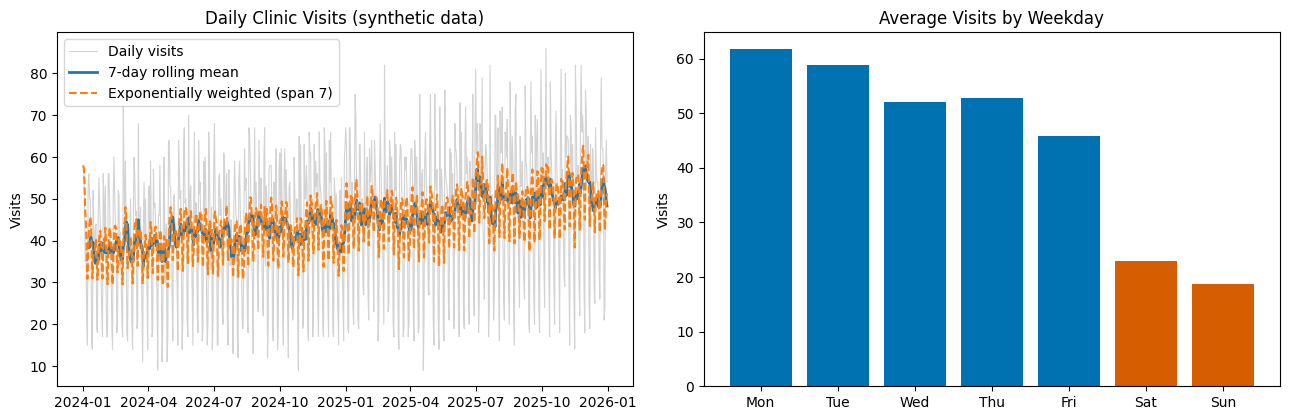

In [12]:
rng = np.random.default_rng(SEED)
days = pd.date_range("2024-01-01", "2025-12-31", freq="D")
weekday_effect = np.array([1.3, 1.2, 1.1, 1.1, 1.0, 0.5, 0.4])             # Monday ... Sunday
expected = np.linspace(40, 55, len(days)) * weekday_effect[days.dayofweek]
ts = pd.Series(rng.poisson(expected).astype(float), index=days, name="visits")

# resample: change the time frequency
weekly  = ts.resample("W").sum()
monthly = ts.resample("MS").agg(["sum", "mean", "max"])
assert weekly.sum() == ts.sum() and monthly["sum"].sum() == ts.sum()        # nothing lost when aggregating

# rolling / exponentially weighted averages smooth the noise
roll7 = ts.rolling(7).mean()
ewm7  = ts.ewm(span=7).mean()

# shift / pct_change: compare with the past
yoy_growth = monthly["sum"].pct_change(12).dropna()                          # vs the same month a year earlier

# groupby on the calendar: seasonality profile
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_profile = ts.groupby(ts.index.day_name()).mean().reindex(order)

# gaps: knock out 12 random days, then fill by interpolation and compare with the truth
gap_days = ts.sample(12, random_state=SEED).index
ts_gappy = ts.copy(); ts_gappy.loc[gap_days] = np.nan
filled = ts_gappy.interpolate(method="time")
fill_mae = (filled.loc[gap_days] - ts.loc[gap_days]).abs().mean()
naive_mae = (ts.mean() - ts.loc[gap_days]).abs().mean()
dow_fill = ts_gappy.fillna(ts_gappy.groupby(ts_gappy.index.dayofweek).transform("mean"))     # use the same weekday's average
dow_mae = (dow_fill.loc[gap_days] - ts.loc[gap_days]).abs().mean()

print(f"Daily observations: {len(ts)} | weeks: {len(weekly)} | months: {len(monthly)}")
print("\nFirst months:"); display(monthly.head(4))
print(f"Year-over-year growth in monthly visits: mean {yoy_growth.mean() * 100:.1f}%")
print("\nAverage visits by weekday:"); print(weekday_profile.round(1).to_string())
print("\nGap filling (12 missing days), average error in visits:")
print(f"  overall mean        : {naive_mae:.1f}")
print(f"  time interpolation  : {fill_mae:.1f}")
print(f"  same-weekday average: {dow_mae:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(ts.index, ts, color="lightgrey", linewidth=0.8, label="Daily visits")
axes[0].plot(roll7.index, roll7, linewidth=2, label="7-day rolling mean")
axes[0].plot(ewm7.index, ewm7, linewidth=1.5, linestyle="--", label="Exponentially weighted (span 7)")
axes[0].set(title="Daily Clinic Visits (synthetic data)", ylabel="Visits"); axes[0].legend()
axes[1].bar(range(7), weekday_profile.values, color=["#0072B2"] * 5 + ["#D55E00"] * 2)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels([d[:3] for d in order])
axes[1].set(title="Average Visits by Weekday", ylabel="Visits")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_time_series_resample_rolling.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation.** The time-series tools each answer a different question. **`resample`** changed the frequency (daily to weekly and monthly) without losing any visits (both totals are asserted equal to the daily total). **Rolling and exponentially weighted means** remove the weekday noise so the slow upward trend becomes visible; the monthly totals grow about **18% year over year**. **Grouping by day name** recovers the built-in weekly pattern (weekdays around 54 visits, weekends around 21). Finally, three ways of **filling 12 deleted days** were compared against the known truth: the overall mean (average error 18.7 visits), time-aware interpolation (12.8) and the average of the **same weekday** (6.6). Interpolation helps only modestly because it ignores the weekly pattern (a missing Saturday sits between busy Friday and quiet Sunday), whereas the weekday-aware fill is best because it uses what is known about the data's structure. The general lesson is that **domain structure beats a generic method**. (Because this data is synthetic, the exercise shows how the tools work, not a real finding.)

### Exercise 3.4 – Reshaping, MultiIndex and merging with validation

In [13]:
pivot = patients.pivot_table(values="target", index="bmi_band", columns="age_group", aggfunc="mean", observed=True)
counts = pd.crosstab(patients["bmi_band"], patients["age_group"], margins=True)
print("Mean progression by BMI band (rows) and age group (columns):")
display(pivot.round(0))
print("Patient counts (note the thin cells):")
display(counts)

# melt: wide -> long (the shape that Seaborn and SQL prefer)
long = pivot.reset_index().melt(id_vars="bmi_band", var_name="age_group", value_name="mean_progression").dropna()

# MultiIndex: two grouping keys, then slice and reshape
multi = patients.groupby(["sex_group", "bmi_band"], observed=True)["target"].agg(["count", "mean"]).round(1)
print("MultiIndex result:"); display(multi)
print("Only the Obese rows (cross-section with .xs):"); display(multi.xs("Obese", level="bmi_band"))
print("Unstacked: sex_group as columns:"); display(multi["mean"].unstack("sex_group"))

# merge: attach each band's average to its patients, checking the relationship is many-to-one
band_ref = by_band[["mean_progression"]].rename(columns={"mean_progression": "band_mean"})
merged = patients.merge(band_ref, left_on="bmi_band", right_index=True, how="left", validate="m:1")
merged["vs_band_mean"] = merged["target"] - merged["band_mean"]
assert len(merged) == len(patients) and merged["band_mean"].notna().all()
print(f"Merged rows: {len(merged)} (unchanged) | mean deviation from band mean: {merged['vs_band_mean'].mean():.3f}")

Mean progression by BMI band (rows) and age group (columns):


age_group,<30,30-39,40-49,50-59,60+
bmi_band,,,,,
Underweight,99.0,NaN,NaN,NaN,NaN
Normal,109.0,98.0,98.0,112.0,132.0
Overweight,164.0,158.0,137.0,179.0,170.0
Obese,175.0,186.0,213.0,229.0,227.0


Patient counts (note the thin cells):


age_group,<30,30-39,40-49,50-59,60+,All
bmi_band,,,,,,
Underweight,2,0,0,0,0,2
Normal,28,32,44,47,35,186
Overweight,8,23,27,53,44,155
Obese,6,18,26,25,24,99
All,44,73,97,125,103,442


MultiIndex result:


count   mean
sex_group bmi_band                 
Group 1   Normal         108  112.5
          Overweight      73  166.9
          Obese           54  197.9
Group 2   Underweight      2   99.0
          Normal          78  105.1
          Overweight      82  163.3
          Obese           45  231.9

Only the Obese rows (cross-section with .xs):


,count,mean
sex_group,,
Group 1,54,197.9
Group 2,45,231.9


Unstacked: sex_group as columns:


sex_group,Group 1,Group 2
bmi_band,,
Underweight,NaN,99.0
Normal,112.5,105.1
Overweight,166.9,163.3
Obese,197.9,231.9


Merged rows: 442 (unchanged) | mean deviation from band mean: 0.011


**Observation.** The pivot table and cross-tab show a limit of the data: some BMI-by-age cells contain only a handful of patients (or none: `NaN`), so those means must not be over-interpreted. `melt` converted the wide table to long form, `MultiIndex` with `.xs()` and `.unstack()` let one result be sliced and rearranged without recomputing, and `merge(..., validate="m:1")` made Pandas **check** that every patient matches exactly one band row; had the lookup contained a duplicate band, the call would have raised an error instead of silently duplicating patients. The row count stayed at 442 and the deviations from the band mean average to 0.011, as they must.

### Exercise 3.5 – Efficiency: memory and vectorization

In [14]:
before = patients.memory_usage(deep=True).sum()
optimised = patients.assign(
    age=patients["age"].astype("int8"),
    sex_group=patients["sex_group"].astype("category"),
    **{c: patients[c].astype("float32") for c in ["bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6", "ldl_hdl_ratio"]},
)
after = optimised.memory_usage(deep=True).sum()
assert np.allclose(optimised["bmi"], patients["bmi"], rtol=1e-6) and (optimised["age"] == patients["age"]).all()
print(f"Memory: {before / 1024:.1f} KB  ->  {after / 1024:.1f} KB   ({(1 - after / before) * 100:.0f}% smaller, values unchanged)")

n_rep = patients.loc[patients.index.repeat(200)].reset_index(drop=True)            # 88,400 rows for a fair timing
t0 = time.perf_counter(); slow = n_rep.apply(lambda r: r["s2"] / r["s3"], axis=1); t_apply = time.perf_counter() - t0
t0 = time.perf_counter(); fast = n_rep["s2"] / n_rep["s3"];                        t_vec = time.perf_counter() - t0
assert np.allclose(slow, fast)
print(f"Row-wise apply: {t_apply * 1000:8.1f} ms | vectorized: {t_vec * 1000:6.2f} ms  ->  {t_apply / t_vec:,.0f}x faster ({len(n_rep):,} rows)")

patients.to_csv(PROC_DIR / "patients_clean.csv", index=False)
print("Saved data/processed/patients_clean.csv")

Memory: 78.4 KB  ->  36.2 KB   (54% smaller, values unchanged)
Row-wise apply:    426.6 ms | vectorized:   0.46 ms  ->  934x faster (88,400 rows)
Saved data/processed/patients_clean.csv


**Observation.** Choosing smaller data types (`int8` for age, `float32` for measurements) and the `category` type for repeated labels cut memory by **54%** without changing the values (verified). The speed comparison is the most important habit in this section: the row-wise `apply` took about **934 times longer** than the equivalent vectorized column division on 88,400 rows, with identical results. The rule is to **think in columns, not rows**. The cleaned table is saved for later sections.

---
# 4. SQL: Querying Data with SQLite

SQL remains the most widely required data skill. Python ships with **SQLite**, a real SQL engine, so these queries run exactly as they would in a company database (with small dialect differences). Every important query is **cross-checked against Pandas**, which both proves correctness and shows how the two tools relate.

### Exercise 4.1 – Create a database, tables and a lookup table

In [15]:
from dstoolkit import df_to_sqlite, run_query, explain

conn = sqlite3.connect(":memory:")
patients_sql = patients[["patient_id", "age", "sex_group", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6", "target", "bmi_band", "age_group"]].astype(
    {"bmi_band": str, "age_group": str})
n_rows = df_to_sqlite(patients_sql, "patients", conn)

conn.executescript("""
CREATE TABLE bmi_bands (
    band      TEXT PRIMARY KEY,
    lower     REAL NOT NULL,
    upper     REAL NOT NULL,
    who_label TEXT NOT NULL
);
INSERT INTO bmi_bands VALUES
    ('Underweight',  0.0, 18.5, 'Below healthy weight'),
    ('Normal',      18.5, 25.0, 'Healthy weight'),
    ('Overweight',  25.0, 30.0, 'Above healthy weight'),
    ('Obese',       30.0, 100., 'Obesity range');
""")

print(f"Loaded {n_rows} patients into SQLite {sqlite3.sqlite_version}")
print("\nTables and columns:")
for (tbl,) in conn.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name"):
    cols = [r[1] for r in conn.execute(f"PRAGMA table_info({tbl})")]
    print(f"  {tbl:<10}", cols)

Loaded 442 patients into SQLite 3.45.1

Tables and columns:
  bmi_bands  ['band', 'lower', 'upper', 'who_label']
  patients   ['patient_id', 'age', 'sex_group', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target', 'bmi_band', 'age_group']


**Observation.** The patient table was written with `df_to_sqlite` (from the project's own package) and a second, hand-written **lookup table** was created with `CREATE TABLE`, a `PRIMARY KEY` and `NOT NULL` constraints: the way reference data lives in a real database. `PRAGMA table_info` lists the schema (442 patient rows loaded).

### Exercise 4.2 – Core queries: filter, aggregate, CASE, JOIN
All queries are collected in a dictionary, executed with `run_query`, and finally saved to `sql/patient_analytics.sql` as a portfolio file.

In [16]:
QUERIES = {}

QUERIES["highest_progression_obese_under_50"] = """
-- Obese patients younger than 50 with the highest disease progression
SELECT patient_id, age, bmi, target
FROM patients
WHERE bmi >= 30 AND age < 50
ORDER BY target DESC
LIMIT 5
"""

QUERIES["band_summary"] = """
-- Summary per BMI band (GROUP BY + HAVING filters whole groups)
SELECT bmi_band,
       COUNT(*)                 AS patients,
       ROUND(AVG(target), 1)    AS mean_progression,
       MIN(target)              AS min_progression,
       MAX(target)              AS max_progression,
       ROUND(AVG(age), 1)       AS mean_age
FROM patients
GROUP BY bmi_band
HAVING COUNT(*) >= 20
ORDER BY mean_progression DESC
"""

QUERIES["severity_levels"] = """
-- CASE turns a number into labelled categories
SELECT CASE WHEN target < 100 THEN '1 Low (<100)'
            WHEN target < 200 THEN '2 Medium (100-199)'
            ELSE                   '3 High (200+)' END AS severity,
       COUNT(*)              AS patients,
       ROUND(AVG(bmi), 1)    AS mean_bmi
FROM patients
GROUP BY severity
ORDER BY severity
"""

QUERIES["join_with_lookup"] = """
-- JOIN with the lookup table to attach a readable label
SELECT b.who_label, COUNT(*) AS patients, ROUND(AVG(p.target), 1) AS mean_progression
FROM patients AS p
JOIN bmi_bands AS b ON p.bmi_band = b.band
GROUP BY b.who_label
ORDER BY mean_progression DESC
"""

for name in ["highest_progression_obese_under_50", "band_summary", "severity_levels", "join_with_lookup"]:
    print(f"--- {name} ---")
    display(run_query(conn, QUERIES[name]))

# Cross-check 1: SQL aggregation == Pandas groupby
sql_band = run_query(conn, QUERIES["band_summary"]).set_index("bmi_band")
pd_band = by_band.set_axis(by_band.index.astype(str))                    # plain-string index so both frames compare cleanly
common = sql_band.index.intersection(pd_band.index)
excluded = sorted(set(pd_band.index) - set(sql_band.index))              # bands removed by HAVING COUNT(*) >= 20
assert len(common) == len(sql_band) and (pd_band.loc[excluded, "patients"] < 20).all()
print(f"HAVING COUNT(*) >= 20 removed: {excluded} (patients in them: {pd_band.loc[excluded, 'patients'].tolist()})")
assert (sql_band.loc[common, "patients"] == pd_band.loc[common, "patients"]).all()
assert np.allclose(sql_band.loc[common, "mean_progression"], pd_band.loc[common, "mean_progression"], atol=0.051)
print("Cross-check passed: SQL GROUP BY gives the same counts and means as Pandas groupby")

# Cross-check 2: the join must not lose or duplicate patients
orphans = conn.execute("SELECT COUNT(*) FROM patients p LEFT JOIN bmi_bands b ON p.bmi_band = b.band WHERE b.band IS NULL").fetchone()[0]
joined_total = run_query(conn, QUERIES["join_with_lookup"])["patients"].sum()
print(f"Patients without a matching band: {orphans} | patients after the join: {joined_total} of {n_rows}")
assert orphans == 0 and joined_total == n_rows

--- highest_progression_obese_under_50 ---


,patient_id,age,bmi,target
0,257,35.0,41.3,346.0
1,142,41.0,30.8,317.0
2,10,29.0,30.0,310.0
3,263,44.0,38.2,308.0
4,337,43.0,34.3,306.0


--- band_summary ---


,bmi_band,patients,mean_progression,min_progression,max_progression,mean_age
0,Obese,99,213.3,52.0,346.0,49.0
1,Overweight,155,165.0,25.0,311.0,51.4
2,Normal,186,109.4,37.0,281.0,46.1


--- severity_levels ---


,severity,patients,mean_bmi
0,1 Low (<100),147,23.8
1,2 Medium (100-199),168,26.0
2,3 High (200+),127,29.8


--- join_with_lookup ---


,who_label,patients,mean_progression
0,Obesity range,99,213.3
1,Above healthy weight,155,165.0
2,Healthy weight,186,109.4
3,Below healthy weight,2,99.0


HAVING COUNT(*) >= 20 removed: ['Underweight'] (patients in them: [2])
Cross-check passed: SQL GROUP BY gives the same counts and means as Pandas groupby
Patients without a matching band: 0 | patients after the join: 442 of 442


**Observation.** The four queries show the four basic building blocks of SQL: **`WHERE` / `ORDER BY` / `LIMIT`** to filter and rank, **`GROUP BY` + `HAVING`** to summarize and then keep only groups with at least 20 patients (the HAVING clause is applied *after* aggregation, unlike WHERE), **`CASE`** to create categories, and **`JOIN`** to attach reference data. Two cross-checks passed: the SQL aggregation reproduces the Pandas `groupby` (same counts, same means), while the `HAVING` clause removed exactly the band(s) with fewer than 20 patients (Underweight: 2 patients); and the `LEFT JOIN ... WHERE b.band IS NULL` check found **0 orphan patients**, so the inner join loses nobody. Looking for unmatched rows before trusting a join is a habit worth keeping. Note that the severity breakdown shows a clear gradient: the mean BMI rises from 23.8 in the low-progression group to 29.8 in the high-progression group.

### Exercise 4.3 – Advanced SQL: CTEs, window functions and subqueries

In [17]:
QUERIES["top2_per_band"] = """
-- CTE + window function: rank patients inside their own BMI band
WITH ranked AS (
    SELECT patient_id, bmi_band, target,
           RANK() OVER (PARTITION BY bmi_band ORDER BY target DESC) AS rnk,
           ROUND(AVG(target) OVER (PARTITION BY bmi_band), 1)        AS band_avg
    FROM patients
)
SELECT * FROM ranked WHERE rnk <= 2 ORDER BY bmi_band, rnk
"""

QUERIES["bmi_quartiles"] = """
-- NTILE splits patients into equal-sized groups by BMI
SELECT quartile,
       COUNT(*)               AS patients,
       ROUND(MIN(bmi), 1)     AS min_bmi,
       ROUND(MAX(bmi), 1)     AS max_bmi,
       ROUND(AVG(target), 1)  AS mean_progression
FROM (SELECT bmi, target, NTILE(4) OVER (ORDER BY bmi) AS quartile FROM patients)
GROUP BY quartile
ORDER BY quartile
"""

QUERIES["above_band_average"] = """
-- Correlated subquery: patients whose progression exceeds the average of their own band
SELECT COUNT(*) AS above_band_average
FROM patients AS p
WHERE target > (SELECT AVG(target) FROM patients WHERE bmi_band = p.bmi_band)
"""

QUERIES["smoothed_progression"] = """
-- Moving average over a window of 29 neighbouring patients, ordered by BMI
SELECT patient_id, bmi, target,
       ROUND(AVG(target) OVER (ORDER BY bmi, patient_id ROWS BETWEEN 14 PRECEDING AND 14 FOLLOWING), 1) AS smoothed_progression
FROM patients
ORDER BY bmi, patient_id
"""

top2 = run_query(conn, QUERIES["top2_per_band"]);       print("Top 2 patients per band:");      display(top2)
quart = run_query(conn, QUERIES["bmi_quartiles"]);      print("BMI quartiles (NTILE):");        display(quart)
above_sql = int(run_query(conn, QUERIES["above_band_average"]).iloc[0, 0])
smooth = run_query(conn, QUERIES["smoothed_progression"])

# Cross-checks against Pandas
sql_rank1 = set(map(tuple, top2.loc[top2["rnk"] == 1, ["bmi_band", "patient_id"]].to_numpy()))
pd_rank1 = set(map(tuple, patients.loc[patients["rank_in_band"] == 1, ["bmi_band", "patient_id"]].astype({"bmi_band": str}).to_numpy()))
above_pd = int((patients["target"] > patients.groupby("bmi_band", observed=True)["target"].transform("mean")).sum())
assert sql_rank1 == pd_rank1
assert above_sql == above_pd
print(f"\nCross-checks passed: SQL RANK() == Pandas rank; correlated subquery ({above_sql}) == Pandas transform ({above_pd})")

Top 2 patients per band:


,patient_id,bmi_band,target,rnk,band_avg
0,118,Normal,281.0,1,109.4
1,305,Normal,253.0,2,109.4
2,257,Obese,346.0,1,213.3
3,33,Obese,341.0,2,213.3
4,360,Overweight,311.0,1,165.0
5,103,Overweight,302.0,2,165.0
6,382,Underweight,104.0,1,99.0
7,282,Underweight,94.0,2,99.0


BMI quartiles (NTILE):


,quartile,patients,min_bmi,max_bmi,mean_progression
0,1,111,18.0,23.2,102.9
1,2,111,23.2,25.7,123.5
2,3,110,25.7,29.3,173.5
3,4,110,29.4,42.2,209.3



Cross-checks passed: SQL RANK() == Pandas rank; correlated subquery (209) == Pandas transform (209)


**Observation.** These are the queries that separate beginners from confident SQL users. A **CTE** (`WITH ranked AS ...`) names an intermediate result so the final query stays readable. **Window functions** (`RANK() OVER (PARTITION BY ...)`, `AVG() OVER (...)`) compute per-group values *without collapsing the rows*, which is why every patient keeps their identity while also showing their band average. `NTILE(4)` split the patients into four equal groups by BMI, and the average progression rises across the quartiles from **102.9** to **209.3**. The correlated subquery counted **209 patients above their own band's average**, and both it and the `RANK()` result matched the Pandas equivalents exactly. Knowing that the same question can be answered in SQL *or* Pandas, and being able to verify one against the other, is a practical strength.

### Exercise 4.4 – Indexes, query plans, transactions and safe parameters

In [18]:
q = "SELECT AVG(target) FROM patients WHERE bmi_band = ?"
plan_before = explain(conn, q, ("Obese",))
conn.execute("CREATE INDEX idx_patients_band ON patients(bmi_band)")
plan_after = explain(conn, q, ("Obese",))
print("Query plan BEFORE the index:", plan_before)
print("Query plan AFTER  the index:", plan_after)

# Transaction: all-or-nothing. The insert is rolled back because an error occurs before the commit.
before = conn.execute("SELECT COUNT(*) FROM patients").fetchone()[0]
try:
    with conn:
        conn.execute("INSERT INTO patients (patient_id, age, target, bmi_band) VALUES (9999, 40, 100.0, 'Normal')")
        raise RuntimeError("simulated failure after the insert")
except RuntimeError as err:
    print(f"\nError raised: {err}")
after = conn.execute("SELECT COUNT(*) FROM patients").fetchone()[0]
print(f"Rows before: {before} | after the failed transaction: {after}  -> rolled back: {before == after}")

# Parameterised queries: values are bound, never pasted into the SQL text
safe = run_query(conn, "SELECT COUNT(*) AS patients, ROUND(AVG(target), 1) AS mean_progression FROM patients WHERE bmi >= ? AND age BETWEEN ? AND ?", (30, 40, 59))
attack = "Obese'; DROP TABLE patients; --"
blocked = run_query(conn, "SELECT COUNT(*) AS n FROM patients WHERE bmi_band = ?", (attack,))
print("\nParameterised query (BMI >= 30, age 40-59):"); display(safe)
print(f"Injection attempt treated as plain text -> {int(blocked.iloc[0, 0])} matches; table still has {conn.execute('SELECT COUNT(*) FROM patients').fetchone()[0]} rows")

Query plan BEFORE the index: ['SCAN patients']
Query plan AFTER  the index: ['SEARCH patients USING INDEX idx_patients_band (bmi_band=?)']

Error raised: simulated failure after the insert
Rows before: 442 | after the failed transaction: 442  -> rolled back: True

Parameterised query (BMI >= 30, age 40-59):


,patients,mean_progression
0,51,221.2


Injection attempt treated as plain text -> 0 matches; table still has 442 rows


**Observation.** `EXPLAIN QUERY PLAN` shows what the database actually does. Before the index it must **SCAN** every row; after `CREATE INDEX` the plan changes to an index **SEARCH** (`SEARCH patients USING INDEX idx_patients_band (bmi_band=?)`), the difference between reading all 442 rows and jumping straight to the matching ones, which matters enormously on tables with millions of rows. The **transaction** guaranteed all-or-nothing behaviour: the failed insert was rolled back automatically (row count unchanged at 442). Finally, **parameterised queries** (`?` placeholders) treat user input as data, so the classic SQL-injection string was just a harmless value that matched nothing, and the table survived. Building SQL by pasting strings together is one of the most common security mistakes, and it is avoided here by design.

### Exercise 4.5 – Save the SQL as a portfolio file and re-run it from disk

Saved sql/patient_analytics.sql with 8 named queries (76 lines). Re-run from disk:
  highest_progression_obese_under_50       -> 5 rows
  band_summary                             -> 3 rows
  severity_levels                          -> 3 rows
  join_with_lookup                         -> 4 rows
  top2_per_band                            -> 8 rows
  bmi_quartiles                            -> 4 rows
  above_band_average                       -> 1 rows
  smoothed_progression                     -> 442 rows


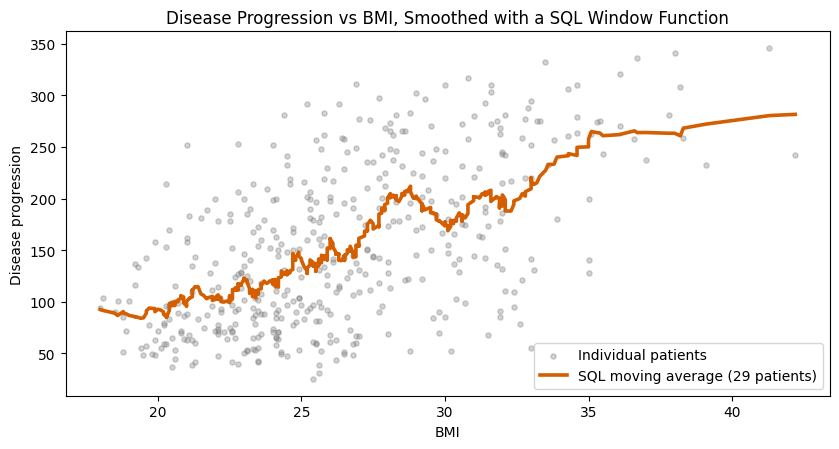

In [19]:
header = "-- Patient analytics queries for the Data Science Tool Mastery project (SQLite dialect)\n-- Tables: patients(patient_id, age, sex_group, bmi, ..., target, bmi_band, age_group), bmi_bands(band, lower, upper, who_label)\n\n"
body = "\n\n".join(f"-- name: {name}{sql.rstrip()}" if sql.startswith("\n") else f"-- name: {name}\n{sql.rstrip()}" for name, sql in QUERIES.items())
(SQL_DIR / "patient_analytics.sql").write_text(header + body + "\n")

# Prove the saved file works: parse the named queries back and execute every one of them
text = (SQL_DIR / "patient_analytics.sql").read_text()
parsed = {}
for chunk in text.split("-- name: ")[1:]:
    name, _, sql = chunk.partition("\n")
    parsed[name.strip()] = sql.strip()
results = {name: len(run_query(conn, sql)) for name, sql in parsed.items()}
print(f"Saved sql/patient_analytics.sql with {len(parsed)} named queries ({len(text.splitlines())} lines). Re-run from disk:")
for name, n in results.items():
    print(f"  {name:<40} -> {n} rows")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.scatter(smooth["bmi"], smooth["target"], s=14, alpha=0.35, color="grey", label="Individual patients")
ax.plot(smooth["bmi"], smooth["smoothed_progression"], linewidth=2.6, color="#D55E00", label="SQL moving average (29 patients)")
ax.set(title="Disease Progression vs BMI, Smoothed with a SQL Window Function", xlabel="BMI", ylabel="Disease progression")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "03_sql_window_smoothing.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation.** The queries now live in a documented `.sql` file, and the cell **parses that file back and runs all 8 queries**, so the file is proven to work rather than assumed to. The chart is drawn from a query result: the orange line is the SQL window-function moving average, and it shows the relationship between BMI and progression more clearly than the scatter of individual patients, rising from about 92 at the lowest BMIs to about 282 at the highest (the two ends average fewer than 29 neighbours, so they are less reliable than the middle). The wide grey scatter is a reminder that the trend explains only part of the variation between patients.

---
# 5. Visualization: Matplotlib and Seaborn

Good charts need a consistent style, correct choices and clear annotation. This section builds a **house style** (colour-blind-safe Okabe-Ito colours, minimal clutter) in the project's own package, then uses the two main Python plotting libraries for what each does best: **Matplotlib** for fully controlled, annotated figures, and **Seaborn** for fast statistical graphics.

### Exercise 5.1 – A multi-panel dashboard with the Matplotlib object-oriented API

Saved PNG (raster) and SVG (vector): ['04_dashboard.png', '04_dashboard.svg']


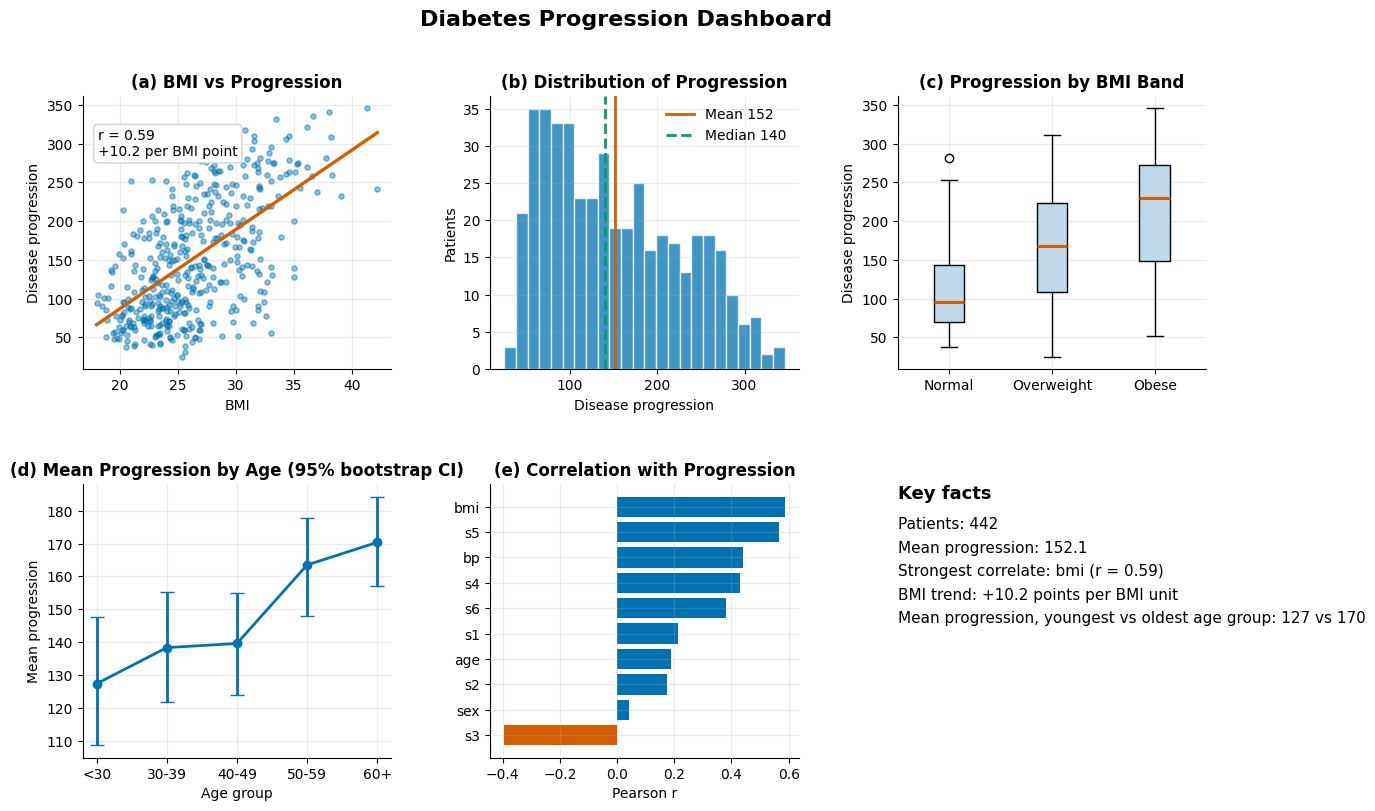

In [20]:
import seaborn as sns
from matplotlib.gridspec import GridSpec
from dstoolkit import set_portfolio_style, save_figure, PALETTE, bootstrap_ci

set_portfolio_style()                                    # one call applies the whole house style

corr_target = raw[FEATURES].corrwith(raw["target"]).sort_values()
r_bmi = raw["bmi"].corr(raw["target"])

fig = plt.figure(figsize=(14.5, 8.6))
gs = GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.32)

# (a) scatter with a fitted trend line
ax = fig.add_subplot(gs[0, 0])
ax.scatter(patients["bmi"], patients["target"], s=14, alpha=0.45, color=PALETTE[0])
slope, intercept = np.polyfit(patients["bmi"], patients["target"], 1)
xs = np.array([patients["bmi"].min(), patients["bmi"].max()])
ax.plot(xs, intercept + slope * xs, color=PALETTE[1], linewidth=2.4)
ax.annotate(f"r = {r_bmi:.2f}\n+{slope:.1f} per BMI point", xy=(0.05, 0.78), xycoords="axes fraction", fontsize=10,
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))
ax.set(title="(a) BMI vs Progression", xlabel="BMI", ylabel="Disease progression")

# (b) distribution with mean and median
ax = fig.add_subplot(gs[0, 1])
ax.hist(patients["target"], bins=24, color=PALETTE[0], alpha=0.75, edgecolor="white")
ax.axvline(patients["target"].mean(), color=PALETTE[1], linewidth=2, label=f"Mean {patients['target'].mean():.0f}")
ax.axvline(patients["target"].median(), color=PALETTE[2], linewidth=2, linestyle="--", label=f"Median {patients['target'].median():.0f}")
ax.set(title="(b) Distribution of Progression", xlabel="Disease progression", ylabel="Patients"); ax.legend()

# (c) box plot by BMI band (bands with at least 20 patients)
ax = fig.add_subplot(gs[0, 2])
bands = [b for b in ["Normal", "Overweight", "Obese"]]
ax.boxplot([patients.loc[patients["bmi_band"] == b, "target"] for b in bands], tick_labels=bands, patch_artist=True,
           boxprops=dict(facecolor="#BFD9EA"), medianprops=dict(color=PALETTE[1], linewidth=2.2))
ax.set(title="(c) Progression by BMI Band", ylabel="Disease progression")

# (d) group means with bootstrap confidence intervals, using the project's own tested function
ax = fig.add_subplot(gs[1, 0])
ages = ["<30", "30-39", "40-49", "50-59", "60+"]
means = [patients.loc[patients["age_group"] == a, "target"].mean() for a in ages]
cis = [bootstrap_ci(patients.loc[patients["age_group"] == a, "target"].to_numpy(), np.mean, n_boot=1000, seed=SEED) for a in ages]
err = np.array([[m - lo, hi - m] for m, (lo, hi) in zip(means, cis)]).T
ax.errorbar(ages, means, yerr=err, fmt="o-", capsize=5, linewidth=2, color=PALETTE[0])
ax.set(title="(d) Mean Progression by Age (95% bootstrap CI)", xlabel="Age group", ylabel="Mean progression")

# (e) correlation of each feature with the target
ax = fig.add_subplot(gs[1, 1])
ax.barh(corr_target.index, corr_target.values, color=[PALETTE[1] if v < 0 else PALETTE[0] for v in corr_target.values])
ax.set(title="(e) Correlation with Progression", xlabel="Pearson r")

# (f) a text panel: charts can carry words as well
ax = fig.add_subplot(gs[1, 2]); ax.axis("off")
ax.text(0, 1, "Key facts", fontsize=13, fontweight="bold", va="top")
ax.text(0, 0.88, f"Patients: {len(patients)}\nMean progression: {patients['target'].mean():.1f}\nStrongest correlate: {corr_target.abs().idxmax()} "
                 f"(r = {corr_target[corr_target.abs().idxmax()]:.2f})\nBMI trend: +{slope:.1f} points per BMI unit\n"
                 f"Mean progression, youngest vs oldest age group: {means[0]:.0f} vs {means[-1]:.0f}", fontsize=11, va="top", linespacing=1.7)
fig.suptitle("Diabetes Progression Dashboard", fontsize=16, fontweight="bold", y=0.98)

save_figure(fig, FIG_DIR / "04_dashboard.png"); save_figure(fig, FIG_DIR / "04_dashboard.svg")
plt.show()
print("Saved PNG (raster) and SVG (vector):", sorted(p.name for p in FIG_DIR.glob("04_dashboard.*")))

**Observation.** A `GridSpec` layout combines six different views on one page, and every element is controlled explicitly (annotations, reference lines, confidence-interval error bars from the project's own `bootstrap_ci`, a text panel). The panels tell a coherent story: progression rises with BMI (r = **0.59**, about **10.2 points per BMI unit**), the distribution of progression is right-skewed (mean 152, median 140), and the strongest single correlate is **`bmi`** (r = 0.59). Panel (d) is a good example of honest charting: mean progression rises with age (from **127** in the youngest group to **170** in the oldest), and the confidence intervals of the youngest and oldest groups do not overlap, so the age trend is real, while neighbouring groups overlap heavily, so individual steps between adjacent age groups should not be over-read. The figure was saved both as **PNG** (for documents) and **SVG** (vector, for crisp printing at any size), and the palette stays distinguishable for people with the most common forms of colour-blindness.

### Exercise 5.2 – Seaborn: statistical graphics in one line each

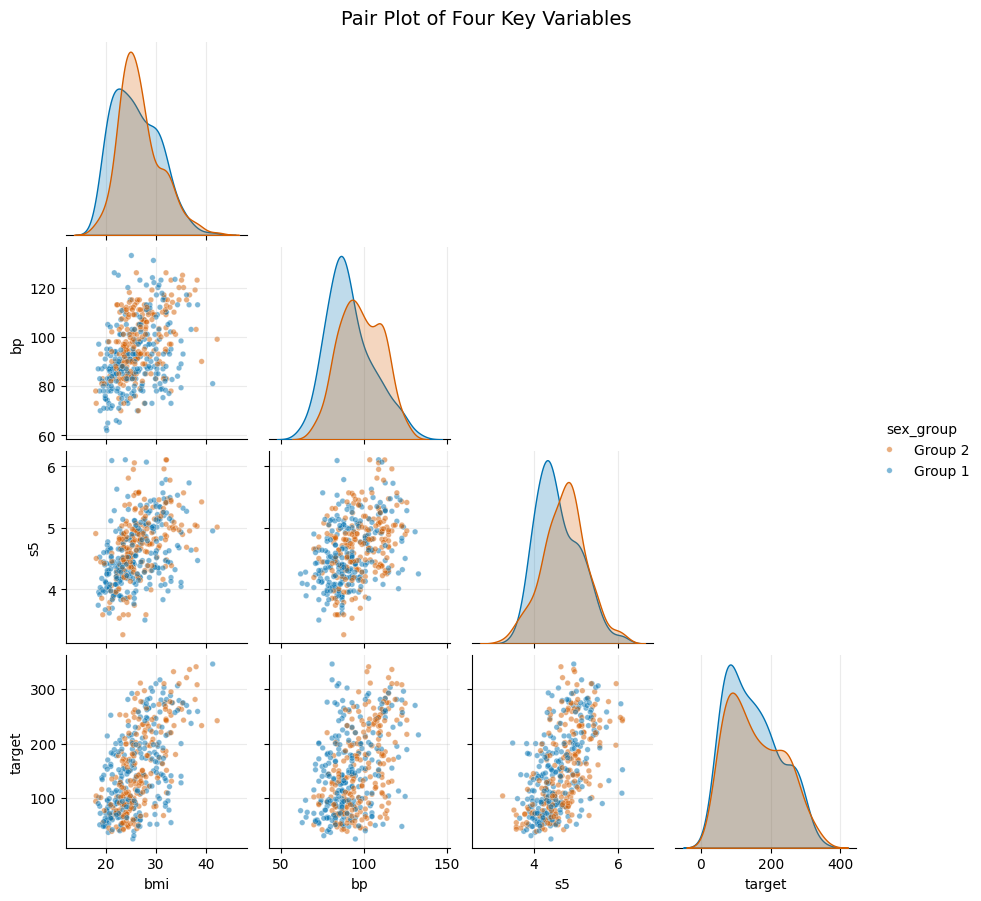

In [21]:
two_colours = {"Group 1": PALETTE[0], "Group 2": PALETTE[1]}

# (a) pair plot: every pairwise relationship at once, split by group
g = sns.pairplot(patients, vars=["bmi", "bp", "s5", "target"], hue="sex_group", palette=two_colours, corner=True,
                 height=2.2, plot_kws={"alpha": 0.5, "s": 16})
g.figure.suptitle("Pair Plot of Four Key Variables", y=1.02, fontsize=14)
save_figure(g.figure, FIG_DIR / "05_seaborn_pairplot.png")
plt.show()

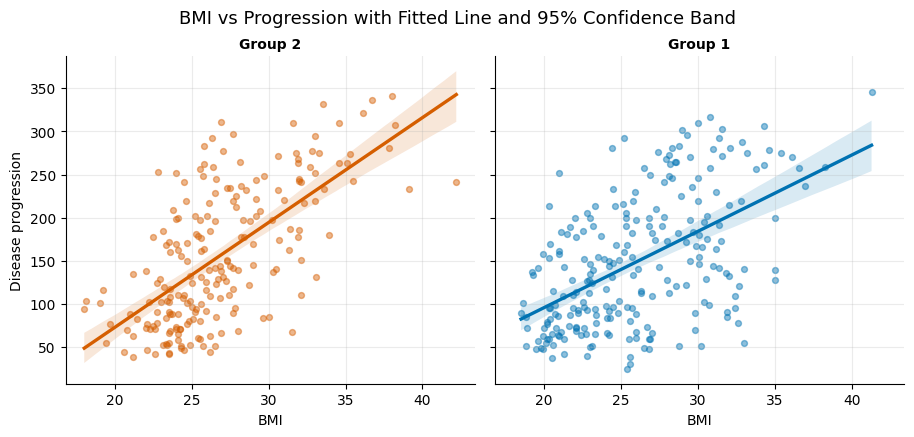

In [22]:
# (b) lmplot: regression line with confidence band, one panel per group
g = sns.lmplot(data=patients, x="bmi", y="target", col="sex_group", hue="sex_group", palette=two_colours,
               height=4.2, aspect=1.1, scatter_kws={"alpha": 0.45, "s": 18}, line_kws={"linewidth": 2.4})
g.set_axis_labels("BMI", "Disease progression"); g.set_titles("{col_name}")
g.figure.suptitle("BMI vs Progression with Fitted Line and 95% Confidence Band", y=1.03, fontsize=13)
save_figure(g.figure, FIG_DIR / "06_seaborn_lmplot.png")
plt.show()

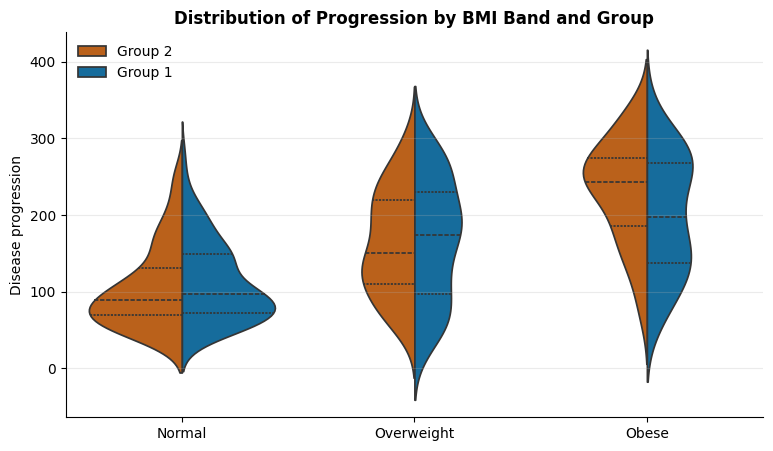

In [23]:
# (c) violin plot with quartiles: full distribution shape per band and group
plot_df = patients[patients["bmi_band"] != "Underweight"].assign(bmi_band=lambda d: d["bmi_band"].cat.remove_unused_categories())
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=plot_df, x="bmi_band", y="target", hue="sex_group", split=True, inner="quartile", palette=two_colours, ax=ax)
ax.set(title="Distribution of Progression by BMI Band and Group", xlabel="", ylabel="Disease progression")
ax.legend(title="")
save_figure(fig, FIG_DIR / "07_seaborn_violin.png")
plt.show()

Order of variables after clustering: ['s3', 'sex', 's1', 's2', 'age', 's4', 's5', 'bmi', 'target', 'bp', 's6']


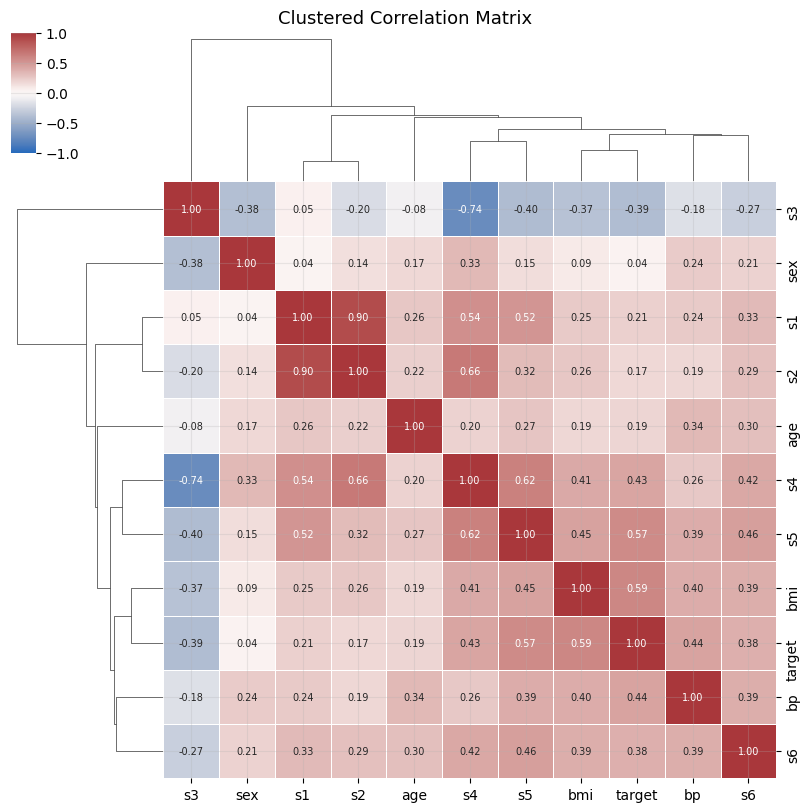

In [24]:
# (d) clustermap: correlation matrix with hierarchical clustering (SciPy runs underneath)
cm = sns.clustermap(raw[FEATURES + ["target"]].corr(), cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
                    annot_kws={"size": 7}, figsize=(8.2, 8), linewidths=0.4, cbar_pos=(0.02, 0.83, 0.03, 0.15))
cm.figure.suptitle("Clustered Correlation Matrix", y=1.01, fontsize=13)
save_figure(cm.figure, FIG_DIR / "08_seaborn_clustermap.png")
order_cols = [cm.data2d.columns[i] for i in range(len(cm.data2d))]
plt.show()
print("Order of variables after clustering:", order_cols)

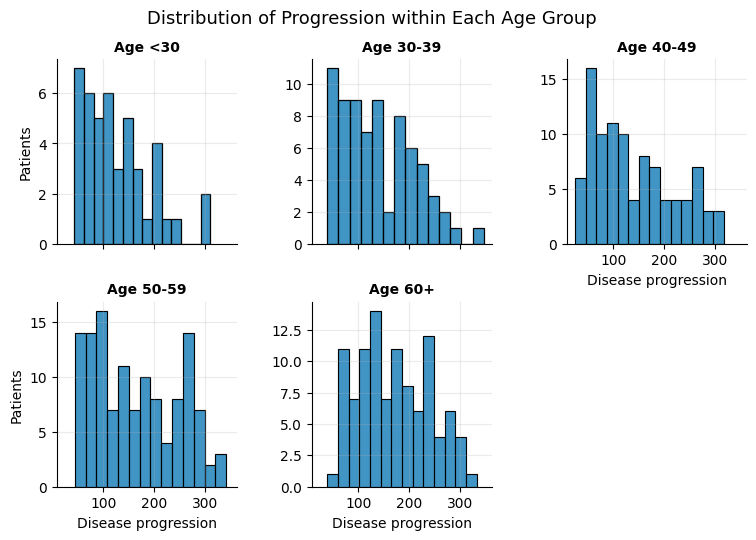

In [25]:
# (e) FacetGrid: the same histogram repeated for each age group
g = sns.FacetGrid(patients, col="age_group", col_wrap=3, height=2.6, sharey=False)
g.map_dataframe(sns.histplot, x="target", bins=14, color=PALETTE[0])
g.set_titles("Age {col_name}"); g.set_axis_labels("Disease progression", "Patients")
g.figure.suptitle("Distribution of Progression within Each Age Group", y=1.03, fontsize=13)
save_figure(g.figure, FIG_DIR / "09_seaborn_facetgrid.png")
plt.show()

**Observation.** Each Seaborn call replaces dozens of lines of Matplotlib. The **pair plot** shows that BMI and the serum measure `s5` both rise with progression and with each other (r = 0.45 between them). The **`lmplot`** draws a regression line with a 95% confidence band per group; the bands widen at extreme BMI values where there are few patients, a feature, not a flaw: it shows where the estimate is uncertain. The **violin plot** shows full distribution shapes, not just medians, and the quartile lines confirm that progression is higher and more spread out in the obese band. The **clustermap** reorders the variables so that correlated ones sit together; the order after clustering starts with `s3` and ends with `s6`, and `s1` and `s2` (total cholesterol and LDL) end up side by side, matching their high correlation found in the VIF analysis of Section 2. The **FacetGrid** repeats one chart across a categorical variable, an effective way to compare subgroups.

**Matplotlib or Seaborn?** Seaborn is faster for statistical exploration; Matplotlib is needed for precise control (annotations, custom layouts, vector export). Seaborn is built on Matplotlib, so mastering both means moving freely between them, as done here.

---
# 6. Scikit-learn: A Complete, Leak-Free Machine Learning Workflow

This is the portfolio centrepiece: predicting **disease progression** from baseline measurements with a professional workflow, namely a pipeline, honest cross-validation, tuning, nested validation, interpretation and a saved, documented model.

### Exercise 6.1 – Split the data and set a baseline
Before any model, one must know **what "no skill" looks like**. The baseline always predicts the average progression; any real model must beat it. The test set is locked away and used **once**, at the end.

In [26]:
from sklearn.model_selection import train_test_split, RepeatedKFold, KFold, cross_validate, cross_val_score, GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import joblib
from dstoolkit import ClinicalFeatureAdder, regression_report

X, y = raw[FEATURES], raw["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Training patients: {len(X_train)} | locked test patients: {len(X_test)}")

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_test = regression_report(y_test, baseline.predict(X_test))
print("\nBaseline (always predict the training mean) on the test set:")
print({k: round(v, 2) for k, v in baseline_test.items()})

Training patients: 353 | locked test patients: 89

Baseline (always predict the training mean) on the test set:
{'rmse': 73.22, 'mae': 64.01, 'median_ae': 63.74, 'r2': -0.01}


**Observation.** The baseline has an RMSE of **73.2** (about the standard deviation of progression itself) and an R-squared of **-0.012**, slightly below zero because the training mean is not exactly the test mean. Any useful model must beat these numbers. Splitting *before* any analysis of the test rows, and not touching the test set again until the end, is what keeps the final score honest.

### Exercise 6.2 – Data leakage: the mistake that makes models look better than they are
*Experiment on synthetic pure-noise data* (the target has no relationship to any feature, so the true R-squared is zero or negative). A **wrong** workflow selects the 10 "best" of 500 features using *all* the data and only then cross-validates; the **right** workflow puts the feature selection inside a pipeline so it is re-done within each training fold. Repeated over 20 random datasets.

In [27]:
wrong_scores, right_scores = [], []
for rep in range(20):
    r = np.random.default_rng(1000 + rep)
    Xn, yn = r.normal(size=(80, 500)), r.normal(size=80)                    # 500 noise features, 80 samples, no real signal
    # WRONG: feature selection sees every label, including those of the future validation folds
    Xsel = SelectKBest(f_regression, k=10).fit_transform(Xn, yn)
    wrong_scores.append(cross_val_score(Ridge(), Xsel, yn, cv=5, scoring="r2").mean())
    # RIGHT: selection happens inside each training fold only
    pipe_ok = Pipeline([("select", SelectKBest(f_regression, k=10)), ("ridge", Ridge())])
    right_scores.append(cross_val_score(pipe_ok, Xn, yn, cv=5, scoring="r2").mean())

print(f"Mean cross-validated R-squared on pure noise, averaged over 20 datasets:")
print(f"  WRONG (select features first, then cross-validate): {np.mean(wrong_scores):+.3f}")
print(f"  RIGHT (selection inside the pipeline)              : {np.mean(right_scores):+.3f}")
print(f"The wrong workflow looked better in {sum(w > r_ for w, r_ in zip(wrong_scores, right_scores))} of 20 experiments")

Mean cross-validated R-squared on pure noise, averaged over 20 datasets:
  WRONG (select features first, then cross-validate): +0.208
  RIGHT (selection inside the pipeline)              : -0.579
The wrong workflow looked better in 20 of 20 experiments


**Observation.** On data that contains **no signal at all**, the leaky workflow reports a cross-validated R-squared of **+0.21**, which looks like a real model, while the correct pipeline reports **-0.58** (zero or negative is the truth, and a negative value means the model is worse than predicting the mean). The leaky version "peeked" at the validation labels when choosing features, so the apparent skill was an illusion. This is the most common serious mistake in applied machine learning, and the cure is simple: **every step that learns from data (scaling, imputing, selecting, encoding) must live inside the `Pipeline`**, so it is fitted on training folds only. All models below follow this rule.

### Exercise 6.3 – Build the pipeline with a custom transformer and `ColumnTransformer`
The pipeline builder has two switches that add the **engineered features** from the project's tested `ClinicalFeatureAdder` (an LDL/HDL ratio and a BMI band). Whether they are worth keeping is decided with evidence in the next exercise.

In [28]:
BASE_NUMERIC = ["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]

def build_pipeline(model, ratio=False, band=False):
    """[custom features ->] preprocessing -> model. `ratio` and `band` switch the engineered features on or off."""
    numeric = BASE_NUMERIC + (["ldl_hdl_ratio"] if ratio else [])
    transformers = [("num", StandardScaler(), numeric), ("sex", OneHotEncoder(drop="if_binary"), ["sex"])]
    if band:
        transformers.append(("band", "passthrough", ["bmi_band"]))           # already an ordinal 0-2 code
    steps = [("prep", ColumnTransformer(transformers)), ("model", model)]
    if ratio or band:
        steps.insert(0, ("features", ClinicalFeatureAdder()))
    return Pipeline(steps)

def input_names(pipe):
    return [n.split("__", 1)[1] for n in pipe[:-1].get_feature_names_out()]

full = build_pipeline(LinearRegression(), ratio=True, band=True).fit(X_train, y_train)
plain = build_pipeline(LinearRegression()).fit(X_train, y_train)
print("With both engineered features:", [name for name, _ in full.steps], "->", len(input_names(full)), "model inputs")
print("   inputs:", input_names(full))
print("Raw features only            :", [name for name, _ in plain.steps], "->", len(input_names(plain)), "model inputs")
full

With both engineered features: ['features', 'prep', 'model'] -> 12 model inputs
   inputs: ['age', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'ldl_hdl_ratio', 'sex_2.0', 'bmi_band']
Raw features only            : ['prep', 'model'] -> 10 model inputs


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,bmi_cutoffs,"(25.0, ...)"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('sex', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

**Observation.** One function builds every variant of the pipeline. With both switches on, the raw 10 columns become **12 model inputs**: the custom `ClinicalFeatureAdder` adds `ldl_hdl_ratio` and `bmi_band`, `StandardScaler` standardizes the numeric columns and `OneHotEncoder` handles the binary `sex` code. With both switched off there are 10 inputs and the custom step is not needed. Because the whole chain is one object, `fit`, `predict`, cross-validation, saving and loading all treat it as a single model: nothing can be forgotten at prediction time, and nothing from the test data can leak into the scaler.

### Exercise 6.4 – Feature ablation: do the engineered features earn their place?
Domain knowledge suggested two extra features, but a feature that sounds sensible is not automatically useful. An **ablation study** adds them one at a time and measures the effect with repeated cross-validation on the **training data only** (the test set is not touched). The decision rule is stated *before* looking at the results: *use the simplest feature set whose RMSE is within 0.5 of the best one.*

,model_inputs,RMSE,RMSE_sd
Raw 10 features,10.0,55.229,3.498
+ LDL/HDL ratio,11.0,55.231,3.413
+ BMI band,11.0,55.087,3.523
+ both engineered,12.0,55.077,3.421


Rule: simplest set within 0.5 RMSE of the best (55.077).  Chosen: 'Raw 10 features'  ->  {'ratio': False, 'band': False}


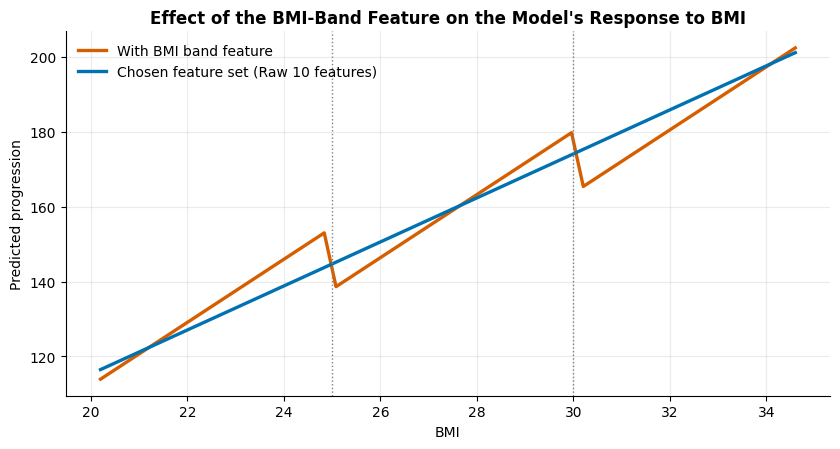

In [29]:
rmse_scoring = "neg_root_mean_squared_error"
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)

variants = {"Raw 10 features": (False, False), "+ LDL/HDL ratio": (True, False), "+ BMI band": (False, True), "+ both engineered": (True, True)}
rows = {}
for name, (use_ratio, use_band) in variants.items():
    res = cross_validate(build_pipeline(Ridge(alpha=1.0), use_ratio, use_band), X_train, y_train, cv=cv, scoring=rmse_scoring)
    n_inputs = build_pipeline(Ridge(alpha=1.0), use_ratio, use_band).fit(X_train, y_train)[:-1].transform(X_train).shape[1]
    rows[name] = {"model_inputs": n_inputs, "RMSE": -res["test_score"].mean(), "RMSE_sd": res["test_score"].std()}
ablation = pd.DataFrame(rows).T

TOL = 0.5
eligible = ablation[ablation["RMSE"] <= ablation["RMSE"].min() + TOL].sort_values(["model_inputs", "RMSE"])
chosen = eligible.index[0]
FEATURE_CFG = dict(zip(["ratio", "band"], variants[chosen]))
make = lambda model: build_pipeline(model, **FEATURE_CFG)            # every later model uses the chosen feature set
display(ablation.round(3))
print(f"Rule: simplest set within {TOL} RMSE of the best ({ablation['RMSE'].min():.3f}).  Chosen: '{chosen}'  ->  {FEATURE_CFG}")

# Interpretability check: what does the BMI band do to the model's behaviour?
from sklearn.inspection import partial_dependence
with_band = build_pipeline(Ridge(alpha=1.0), True, True).fit(X_train, y_train)
chosen_pipe = make(Ridge(alpha=1.0)).fit(X_train, y_train)
pd_a = partial_dependence(with_band, X_train, ["bmi"], grid_resolution=60)
pd_b = partial_dependence(chosen_pipe, X_train, ["bmi"], grid_resolution=60)
grid, avg_a, avg_b = pd_a["grid_values"][0], pd_a["average"][0], pd_b["average"][0]
band_drop = -np.diff(avg_a).min()
chosen_smooth = bool((np.diff(avg_b) >= -1e-9).all())

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(grid, avg_a, linewidth=2.4, label="With BMI band feature", color=PALETTE[1])
ax.plot(grid, avg_b, linewidth=2.4, label=f"Chosen feature set ({chosen})", color=PALETTE[0])
for cut in (25, 30):
    ax.axvline(cut, color="grey", linestyle=":", linewidth=1)
ax.set(title="Effect of the BMI-Band Feature on the Model's Response to BMI", xlabel="BMI", ylabel="Predicted progression"); ax.legend()
plt.tight_layout(); save_figure(fig, FIG_DIR / "10_feature_ablation_bmi_band.png")
plt.show()

**Observation.** The four feature sets give cross-validated RMSEs between **55.08** and **55.23**, a spread of only 0.15 against a fold-to-fold standard deviation of about 3.5. **The engineered features make no measurable difference.** The chart shows something worse for the BMI-band feature: with it, the model's predicted progression **falls by about 14 points** each time BMI crosses 25 or 30 (the dotted lines), because the band duplicates information already in BMI and the model assigns it a negative weight to compensate. That is biologically implausible (progression should not drop when BMI rises). The chosen feature set, **Raw 10 features**, gives a smooth, steadily rising curve.

Following the pre-stated rule, all later models use **Raw 10 features**. This is a **negative result worth reporting**: a sensible-sounding idea was tested, found to add nothing, and dropped. The `ClinicalFeatureAdder` remains in the package because it is a correct, tested and reusable component (and a good demonstration of the custom-transformer pattern), but the evidence says this dataset does not need it. Checking a model's *behaviour* (here with partial dependence) and not only its score is what exposed the problem.

### Exercise 6.5 – Compare eight models fairly with repeated cross-validation
Every model sees the **same folds** (5-fold, repeated 3 times, on the training set only), and results are reported as mean and standard deviation, so a difference can be judged against its noise.

In [30]:
models = {
    "Baseline (mean)":    DummyRegressor(),
    "Linear regression":  LinearRegression(),
    "Ridge (alpha=1)":    Ridge(alpha=1.0),
    "Lasso (alpha=1)":    Lasso(alpha=1.0),
    "ElasticNet":         ElasticNet(alpha=0.5, l1_ratio=0.5),
    "SVR (RBF)":          SVR(C=100, epsilon=10),
    "Random forest":      RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED),
    "Gradient boosting":  GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=SEED),
}
rows = {}
for name, model in models.items():
    res = cross_validate(make(model), X_train, y_train, cv=cv,
                         scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows[name] = {"RMSE": -res["test_rmse"].mean(), "RMSE_sd": res["test_rmse"].std(), "MAE": -res["test_mae"].mean(), "R2": res["test_r2"].mean()}
comparison = pd.DataFrame(rows).T.sort_values("RMSE")
comparison["RMSE (mean +/- sd)"] = comparison.apply(lambda r: f"{r['RMSE']:.1f} +/- {r['RMSE_sd']:.1f}", axis=1)
display(comparison[["RMSE (mean +/- sd)", "MAE", "R2"]].round(3))

,RMSE (mean +/- sd),MAE,R2
Ridge (alpha=1),55.2 +/- 3.5,44.908,0.475
Linear regression,55.2 +/- 3.5,44.927,0.474
Lasso (alpha=1),55.4 +/- 3.3,45.145,0.472
ElasticNet,55.9 +/- 3.2,45.979,0.464
Gradient boosting,57.8 +/- 3.9,47.234,0.422
Random forest,58.4 +/- 3.7,47.864,0.409
SVR (RBF),59.4 +/- 4.5,47.359,0.394
Baseline (mean),78.3 +/- 4.7,66.841,-0.042


**Observation.** All seven real models clearly beat the baseline (RMSE 78.3). The best by cross-validation is **Ridge (alpha=1)** (RMSE 55.2, R-squared 0.47). The three **linear** models are the top three and beat the flexible tree ensembles by about 2.6 RMSE points. That difference is smaller than the fold-to-fold standard deviation (about 3.5), so it should not be over-read, but the result is clear in direction: on this small, noisy dataset with only ten inputs, the more flexible models have no advantage, and the simplest model that does the job is the sensible choice. Reporting the spread (± sd), not just the mean, prevents over-reading tiny differences.

### Exercise 6.6 – Hyperparameter tuning, and nested cross-validation to measure its optimism
Two tuning methods are used: an exhaustive **grid search** for Ridge's one parameter and a **randomized search** for gradient boosting's five. A third step then answers a subtle question: *how optimistic is a score that was selected from many candidates?*

In [31]:
ridge_grid = GridSearchCV(make(Ridge()), {"model__alpha": np.logspace(-2, 3, 30)}, cv=cv,
                          scoring="neg_root_mean_squared_error", return_train_score=True)
ridge_grid.fit(X_train, y_train)

gb_space = {"model__n_estimators": [100, 200, 300, 500], "model__learning_rate": [0.01, 0.02, 0.05, 0.1],
            "model__max_depth": [1, 2, 3], "model__subsample": [0.6, 0.8, 1.0], "model__min_samples_leaf": [1, 5, 10, 20]}
gb_search = RandomizedSearchCV(make(GradientBoostingRegressor(random_state=SEED)), gb_space, n_iter=25, cv=5,
                               scoring="neg_root_mean_squared_error", random_state=SEED)
gb_search.fit(X_train, y_train)

# Nested CV: the outer loop never sees the data the inner search tuned on
inner = GridSearchCV(make(Ridge()), {"model__alpha": np.logspace(-2, 3, 30)}, cv=5, scoring="neg_root_mean_squared_error")
nested = -cross_val_score(inner, X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error")

print(f"Ridge : best alpha = {ridge_grid.best_params_['model__alpha']:.2f} | tuned CV RMSE = {-ridge_grid.best_score_:.2f}")
print(f"GBM   : best settings = { {k.replace('model__', ''): v for k, v in gb_search.best_params_.items()} } | tuned CV RMSE = {-gb_search.best_score_:.2f}")
print(f"\nNested CV estimate for the Ridge tuning procedure: RMSE {nested.mean():.2f} (+/- {nested.std():.2f})")
print(f"Plain tuned-CV score of the same procedure       : RMSE {-ridge_grid.best_score_:.2f}   -> optimism of {nested.mean() + ridge_grid.best_score_:+.2f}")

Ridge : best alpha = 0.53 | tuned CV RMSE = 55.23
GBM   : best settings = {'subsample': 0.6, 'n_estimators': 500, 'min_samples_leaf': 1, 'max_depth': 1, 'learning_rate': 0.02} | tuned CV RMSE = 56.65

Nested CV estimate for the Ridge tuning procedure: RMSE 55.56 (+/- 2.30)
Plain tuned-CV score of the same procedure       : RMSE 55.23   -> optimism of +0.33


**Observation.** Tuning helped the flexible model but not the simple one. Ridge reached an RMSE of **55.23** at alpha = 0.5, essentially the same as the untuned 55.23, because the default was already near the optimum (the validation curve in Exercise 6.8 is flat there). The tuned gradient-boosting model improved from 57.80 to **56.65** but still does not catch up with Ridge. Tuning only pays when the default settings are far from the best ones. The nested cross-validation estimate for the Ridge procedure is **55.56**, which is higher than the tuned score by **0.33**: a score that was *selected* as the best of many candidates is slightly optimistic, because part of its apparent advantage is luck. The honest expectation for new patients is therefore the nested figure, not the best inner score.

### Exercise 6.7 – Choose the final model by cross-validation, then use the test set once

In [32]:
candidates = {"Ridge (tuned)": ridge_grid, "Gradient boosting (tuned)": gb_search}
final_name = max(candidates, key=lambda k: candidates[k].best_score_)          # chosen on CROSS-VALIDATION only
final_model = candidates[final_name].best_estimator_
print(f"Final model chosen by cross-validation: {final_name}")

pred_test = final_model.predict(X_test)
final_test = regression_report(y_test, pred_test)
sq_err = (y_test.to_numpy() - pred_test) ** 2
rmse_ci = tuple(np.sqrt(bootstrap_ci(sq_err, np.mean, n_boot=2000, seed=SEED)))   # bootstrap the test errors

summary = pd.DataFrame({"Baseline": baseline_test, "Final model": final_test}).T.round(3)
display(summary)
print(f"Test RMSE {final_test['rmse']:.1f} with a 95% bootstrap interval of [{rmse_ci[0]:.1f}, {rmse_ci[1]:.1f}]")
print(f"Improvement over the baseline: RMSE {(1 - final_test['rmse'] / baseline_test['rmse']) * 100:.0f}% lower")

Final model chosen by cross-validation: Ridge (tuned)


,rmse,mae,median_ae,r2
Baseline,73.222,64.006,63.737,-0.012
Final model,53.805,42.810,37.325,0.454


Test RMSE 53.8 with a 95% bootstrap interval of [46.0, 61.6]
Improvement over the baseline: RMSE 27% lower


**Observation.** The final model (**Ridge (tuned)**) was chosen from the cross-validation results alone, and only then scored on the locked test set: RMSE **53.8**, MAE 42.8, R-squared **0.45**, against a baseline RMSE of 73.2. That is **27% lower error** than guessing the average. The bootstrap interval for the test RMSE ([46.0, 61.6]) is wide because only 89 patients are in the test set, which is an honest reminder that a single test score on a small set is uncertain. The model explains about 45% of the variation in progression on the test set: useful, but far from precise for an individual patient.

### Exercise 6.8 – Diagnostics: is the model behaving, and would more data help?

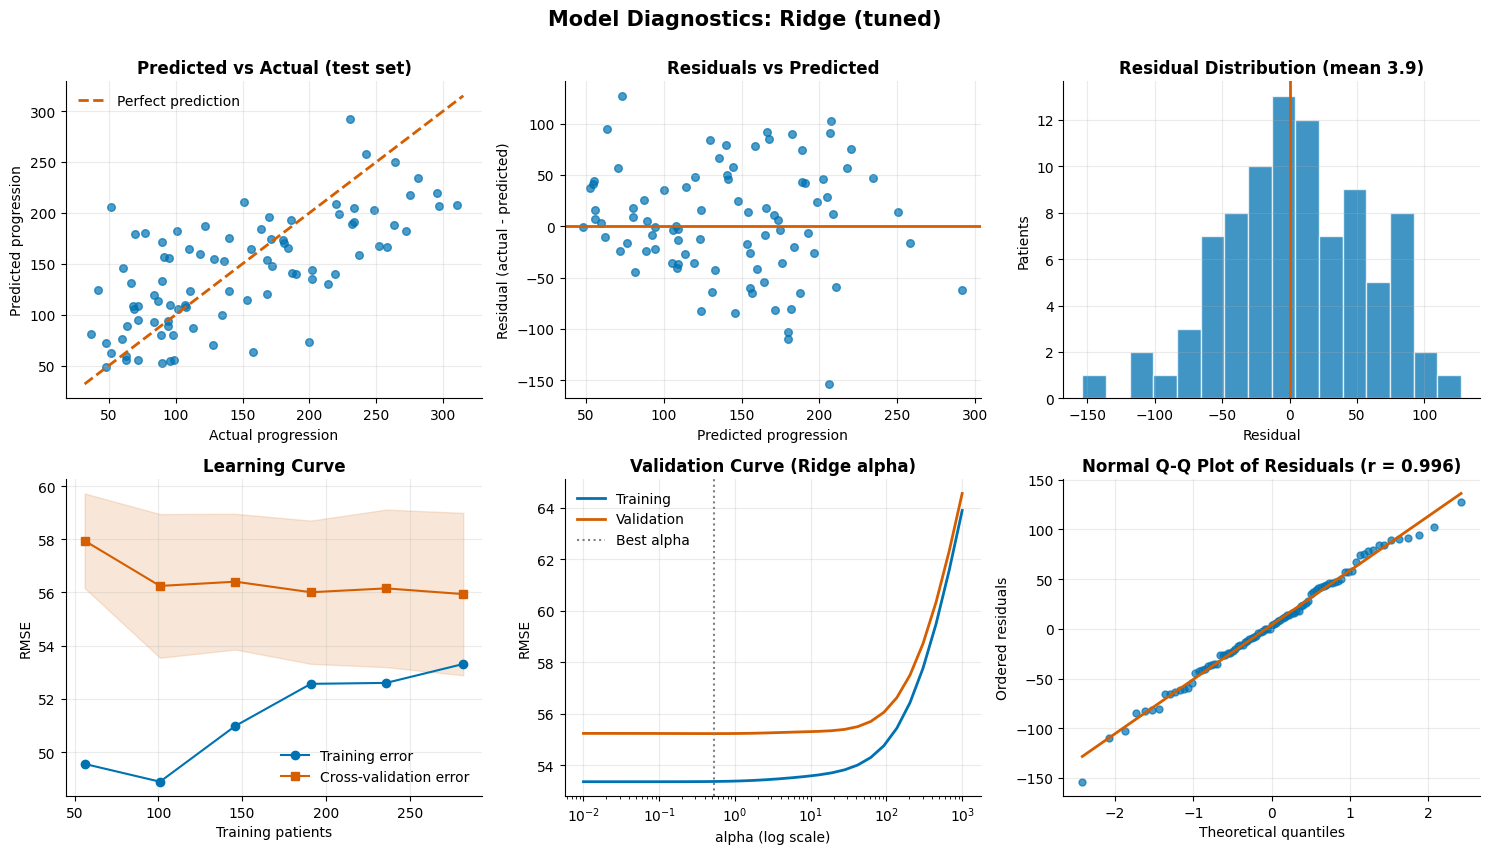

In [33]:
residuals = y_test.to_numpy() - pred_test
sizes, train_sc, val_sc = learning_curve(final_model, X_train, y_train, cv=5, train_sizes=np.linspace(0.2, 1.0, 6),
                                         scoring="neg_root_mean_squared_error", random_state=SEED, shuffle=True)
alphas = ridge_grid.cv_results_["param_model__alpha"].astype(float)
order = np.argsort(alphas)

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
ax = axes[0, 0]
ax.scatter(y_test, pred_test, s=30, alpha=0.7, color=PALETTE[0])
lim = [min(y_test.min(), pred_test.min()) - 5, max(y_test.max(), pred_test.max()) + 5]
ax.plot(lim, lim, color=PALETTE[1], linestyle="--", linewidth=2, label="Perfect prediction")
ax.set(title="Predicted vs Actual (test set)", xlabel="Actual progression", ylabel="Predicted progression"); ax.legend()

ax = axes[0, 1]
ax.scatter(pred_test, residuals, s=30, alpha=0.7, color=PALETTE[0]); ax.axhline(0, color=PALETTE[1], linewidth=2)
ax.set(title="Residuals vs Predicted", xlabel="Predicted progression", ylabel="Residual (actual - predicted)")

ax = axes[0, 2]
ax.hist(residuals, bins=16, color=PALETTE[0], alpha=0.75, edgecolor="white")
ax.axvline(0, color=PALETTE[1], linewidth=2)
ax.set(title=f"Residual Distribution (mean {residuals.mean():.1f})", xlabel="Residual", ylabel="Patients")

ax = axes[1, 0]
ax.plot(sizes, -train_sc.mean(axis=1), "o-", label="Training error", color=PALETTE[0])
ax.plot(sizes, -val_sc.mean(axis=1), "s-", label="Cross-validation error", color=PALETTE[1])
ax.fill_between(sizes, -val_sc.mean(axis=1) - val_sc.std(axis=1), -val_sc.mean(axis=1) + val_sc.std(axis=1), alpha=0.15, color=PALETTE[1])
ax.set(title="Learning Curve", xlabel="Training patients", ylabel="RMSE"); ax.legend()

ax = axes[1, 1]
ax.semilogx(alphas[order], -ridge_grid.cv_results_["mean_train_score"][order], label="Training", color=PALETTE[0], linewidth=2)
ax.semilogx(alphas[order], -ridge_grid.cv_results_["mean_test_score"][order], label="Validation", color=PALETTE[1], linewidth=2)
ax.axvline(ridge_grid.best_params_["model__alpha"], color="grey", linestyle=":", label="Best alpha")
ax.set(title="Validation Curve (Ridge alpha)", xlabel="alpha (log scale)", ylabel="RMSE"); ax.legend()

ax = axes[1, 2]
from scipy import stats
(osm, osr), (slp, icp, rr) = stats.probplot(residuals, dist="norm")
ax.scatter(osm, osr, s=25, alpha=0.7, color=PALETTE[0]); ax.plot(osm, slp * np.array(osm) + icp, color=PALETTE[1], linewidth=2)
ax.set(title=f"Normal Q-Q Plot of Residuals (r = {rr:.3f})", xlabel="Theoretical quantiles", ylabel="Ordered residuals")
fig.suptitle(f"Model Diagnostics: {final_name}", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); save_figure(fig, FIG_DIR / "11_model_diagnostics.png")
plt.show()

**Observation.** Six diagnostics, each answering a different question. **Predicted vs actual:** points follow the diagonal but with wide scatter, and the model under-predicts the highest-progression patients (a common "shrinkage toward the mean"). **Residuals vs predicted:** no strong curve or obvious funnel, so the linear structure is reasonable (a fan shape would signal unequal variance; the formal Breusch-Pagan test in Section 7 does detect *mild* unequal variance on the full data, so the standard errors there should be read with care). **Residual histogram and Q-Q plot:** residuals are centred near zero (mean 3.9) and close to normal in the middle (Q-Q correlation 0.996), with a heavier upper tail. **Learning curve:** the gap between training and cross-validation error is 2.6 RMSE points at the largest size, and the validation error has been essentially **flat** since about 101 training patients (it moved by only 0.3 RMSE points between 101 and 282 patients). More data *of the same kind* would therefore barely help; improving the model would need new information (different measurements), not just more rows. **Validation curve:** error is flat over a wide alpha range and rises when regularization becomes too strong, which explains why tuning gave only a small gain.

### Exercise 6.9 – Interpretation: which measurements matter, and how?

,rmse_increase,sd
s5,18.42,3.14
s1,17.96,3.37
bmi,9.95,2.50
s2,8.32,1.94
sex,3.41,1.09
bp,2.29,2.00
s4,1.55,1.09
s3,1.45,0.59
s6,0.17,0.19
age,-0.20,0.24


Standardized coefficients (change in progression per 1 SD):


,OLS,Ridge (tuned),shrinkage_%
age,1.75,1.78,-1.30
bmi,25.61,25.70,-0.36
bp,16.83,16.76,0.39
s1,-44.45,-38.62,13.12
s2,24.64,20.12,18.36
s3,7.68,5.12,33.30
s4,13.14,12.30,6.40
s5,35.16,32.92,6.38
s6,2.35,2.41,-2.48
sex_2.0,-23.06,-22.86,0.87


Partial dependence rises steadily (monotonic increasing)? {'bmi': True, 's5': True, 'bp': True}


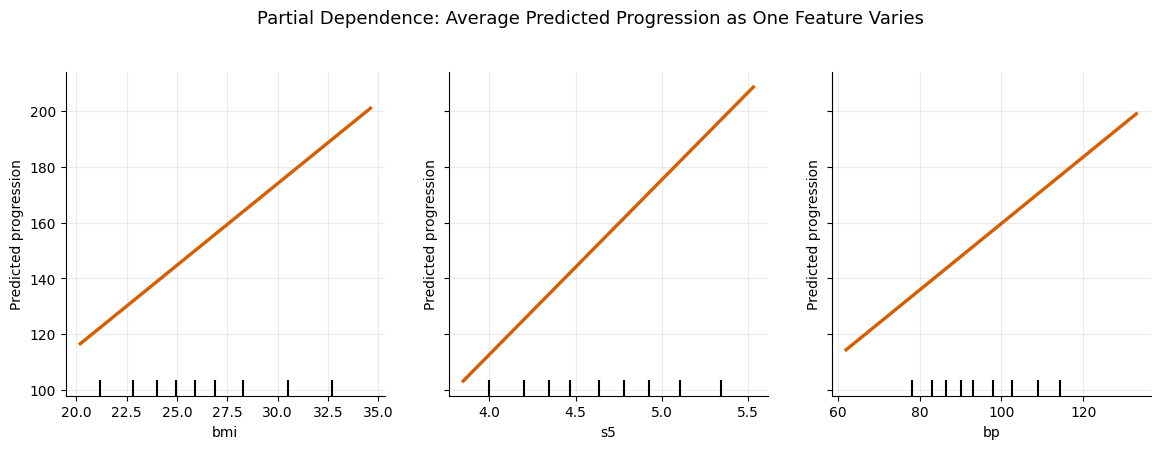

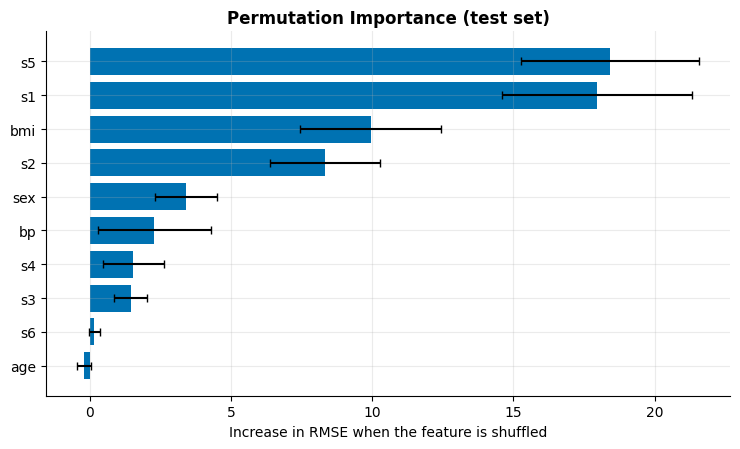

In [34]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({"rmse_increase": perm.importances_mean, "sd": perm.importances_std}, index=FEATURES).sort_values("rmse_increase", ascending=False)
display(imp.round(2))

# Does regularization change the coefficients? Compare plain linear regression with the tuned Ridge model
ols_pipe = make(LinearRegression()).fit(X_train, y_train)
ridge_pipe = ridge_grid.best_estimator_
coef = pd.DataFrame({"OLS": ols_pipe[-1].coef_, "Ridge (tuned)": ridge_pipe[-1].coef_}, index=input_names(ols_pipe))
coef["shrinkage_%"] = (1 - coef["Ridge (tuned)"].abs() / coef["OLS"].abs()) * 100
print("Standardized coefficients (change in progression per 1 SD):")
display(coef.round(2))
s1c, s2c = coef.loc["s1", "Ridge (tuned)"], coef.loc["s2", "Ridge (tuned)"]
opp_note = (f"Note that `s1` and `s2` rank high in importance **together** yet carry **opposite-signed** coefficients ({s1c:.0f} and {s2c:.0f}): "
            "the model is using their *difference*, so shuffling either one breaks that balance. Their individual importance should therefore not be read as "
            "\"cholesterol itself drives progression\". " if s1c * s2c < 0 else "")

pdp_fig, pdp_axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
pd_check = {f: partial_dependence(final_model, X_train, [f], grid_resolution=40)["average"][0] for f in ["bmi", "s5", "bp"]}
monotonic_up = {f: bool((np.diff(v) >= -1e-9).all()) for f, v in pd_check.items()}
print("Partial dependence rises steadily (monotonic increasing)?", monotonic_up)
PartialDependenceDisplay.from_estimator(final_model, X_train, ["bmi", "s5", "bp"], ax=pdp_axes, line_kw={"color": PALETTE[1], "linewidth": 2.4})
pdp_fig.suptitle("Partial Dependence: Average Predicted Progression as One Feature Varies", fontsize=13, y=1.03)
for a in pdp_axes: a.set_ylabel("Predicted progression")
fig2, ax2 = plt.subplots(figsize=(7.5, 4.6))
ax2.barh(imp.index[::-1], imp["rmse_increase"][::-1], xerr=imp["sd"][::-1], color=PALETTE[0], capsize=3)
ax2.set(title="Permutation Importance (test set)", xlabel="Increase in RMSE when the feature is shuffled")
plt.tight_layout()
save_figure(pdp_fig, FIG_DIR / "12_partial_dependence.png"); save_figure(fig2, FIG_DIR / "13_permutation_importance.png")
plt.show()

**Observation.** Three complementary views. **Permutation importance** shuffles one measurement at a time on unseen data and records how much the error grows: the most important are **`s5`** (+18.4 RMSE), **`s1`** (+18.0) and **`bmi`** (+10.0), while `age` hardly matters (the near-zero and slightly negative values for the weakest features are just noise: shuffling a useless feature can by chance help a little). **Partial dependence** shows the *direction*: predicted progression rises steadily with BMI, with `s5` (a triglyceride-related measure) and with blood pressure (checked numerically, no sawtooth artefacts remain now that the BMI band was dropped). **The coefficient comparison** shows the effect of regularization: the unstable, opposing coefficients of the collinear cholesterol measures shrink under Ridge (`s1` by 13%, `s2` by 18% and `s3` by 33%), the problem predicted by the VIF analysis in Section 2. Note that `s1` and `s2` rank high in importance **together** yet carry **opposite-signed** coefficients (-39 and 20): the model is using their *difference*, so shuffling either one breaks that balance. Their individual importance should therefore not be read as "cholesterol itself drives progression". Importance describes what the *model* relies on; it does not prove that changing a measurement would change a patient's outcome (association is not causation).

### Exercise 6.10 – Save the model, reload it, verify it, and document it with a model card

In [35]:
model_path = MODEL_DIR / "diabetes_progression_pipeline.joblib"
joblib.dump(final_model, model_path)
loaded = joblib.load(model_path)

assert np.allclose(loaded.predict(X_test), final_model.predict(X_test))
print(f"Saved {model_path.name} ({model_path.stat().st_size / 1024:.1f} KB). Reloaded model reproduces all {len(X_test)} test predictions exactly.")

new_patients = pd.DataFrame({"age": [45, 62, 38], "sex": [1.0, 2.0, 2.0], "bmi": [24.0, 31.5, 28.0], "bp": [85, 110, 95],
                             "s1": [180, 230, 200], "s2": [100, 140, 115], "s3": [55, 40, 48], "s4": [3.3, 5.8, 4.2],
                             "s5": [4.3, 5.2, 4.7], "s6": [85, 105, 92]})
new_patients["predicted_progression"] = loaded.predict(new_patients[FEATURES]).round(0)
print("\nPredictions for three invented patients (illustration only, not clinical advice):")
display(new_patients[["age", "bmi", "bp", "s5", "predicted_progression"]])

model_card = {
    "model": final_name, "task": "Regression: predict a quantitative measure of diabetes disease progression one year after baseline",
    "dataset": "Diabetes dataset (442 patients), Efron, Hastie, Johnstone and Tibshirani (2004), Annals of Statistics",
    "training_patients": int(len(X_train)), "test_patients": int(len(X_test)), "inputs": FEATURES,
    "pipeline_steps": [name for name, _ in final_model.steps],
    "feature_decision": f"Feature ablation (training data only) kept '{chosen}'; the engineered LDL/HDL ratio and BMI band did not improve cross-validated RMSE and the BMI band caused implausible jumps in predictions.",
    "tuned_parameters": {k: (v.item() if hasattr(v, "item") else v) for k, v in candidates[final_name].best_params_.items()},
    "cross_validation_rmse": round(float(-candidates[final_name].best_score_), 2),
    "test_metrics": {k: round(v, 3) for k, v in final_test.items()}, "test_rmse_95ci": [round(float(x), 1) for x in rmse_ci],
    "baseline_test_rmse": round(baseline_test["rmse"], 2),
    "library_versions": versions, "random_seed": SEED,
    "intended_use": "Teaching and portfolio demonstration of a leak-free machine learning workflow.",
    "not_intended_for": "Clinical decision making. The data is small, from one study, and the model explains only part of the variation.",
    "security_note": "joblib files are pickles: load them only from sources you trust.",
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2))
print("\nmodel_card.json:")
print(json.dumps({k: model_card[k] for k in ["model", "cross_validation_rmse", "test_metrics", "test_rmse_95ci", "intended_use", "not_intended_for"]}, indent=2))

Saved diabetes_progression_pipeline.joblib (3.4 KB). Reloaded model reproduces all 89 test predictions exactly.

Predictions for three invented patients (illustration only, not clinical advice):


,age,bmi,bp,s5,predicted_progression
0,45,24.0,85,4.3,108.0
1,62,31.5,110,5.2,211.0
2,38,28.0,95,4.7,140.0



model_card.json:
{
  "model": "Ridge (tuned)",
  "cross_validation_rmse": 55.23,
  "test_metrics": {
    "rmse": 53.805,
    "mae": 42.81,
    "median_ae": 37.325,
    "r2": 0.454
  },
  "test_rmse_95ci": [
    46.0,
    61.6
  ],
  "intended_use": "Teaching and portfolio demonstration of a leak-free machine learning workflow.",
  "not_intended_for": "Clinical decision making. The data is small, from one study, and the model explains only part of the variation."
}


**Observation.** The saved model reproduces every test prediction exactly after reloading, which is the check that matters: a model that cannot be reloaded and verified is not deployable. Because the **whole pipeline** (custom features, scaling, encoding, model) is one object, predicting for new patients needs only the **raw ten columns**: no manual preprocessing to forget. The **model card** records what the model is for, how it was trained and evaluated, the library versions, and, just as important, **what it must not be used for**. A short security note is included because joblib files are pickles and can run code when loaded: only load model files from trusted sources.

---
# 7. Statistics with SciPy: From "It Looks Different" to Evidence

Charts suggest patterns; statistics says how much confidence they deserve. This section uses **SciPy** for the tests and **NumPy** for the regression inference, built by hand and verified against SciPy and against the bootstrap from Section 2.

### Exercise 7.1 – Hypothesis tests: two groups, three groups, and a categorical association

In [36]:
from scipy import stats
from dstoolkit import holm_adjust, benjamini_hochberg, fisher_z_ci

# ---- Two groups: does mean progression differ between the two sex-code groups?
g1 = patients.loc[patients["sex_group"] == "Group 1", "target"]
g2 = patients.loc[patients["sex_group"] == "Group 2", "target"]
welch = stats.ttest_ind(g2, g1, equal_var=False)
v1, v2, n1, n2 = g1.var(ddof=1), g2.var(ddof=1), len(g1), len(g2)
se_diff = np.sqrt(v1 / n1 + v2 / n2)
df_welch = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
diff = g2.mean() - g1.mean()
ci_diff = diff + np.array([-1, 1]) * stats.t.ppf(0.975, df_welch) * se_diff
assert np.allclose(ci_diff, welch.confidence_interval(0.95))               # my hand calculation == SciPy
d_cohen = diff / np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
mw = stats.mannwhitneyu(g2, g1)
print("TWO GROUPS (Group 2 minus Group 1)")
print(f"  mean progression: {g1.mean():.1f} (n={n1}) vs {g2.mean():.1f} (n={n2});  difference = {diff:.1f}")
print(f"  Welch t-test: t = {welch.statistic:.2f}, p = {welch.pvalue:.3f}  |  95% CI of the difference: [{ci_diff[0]:.1f}, {ci_diff[1]:.1f}]")
print(f"  Mann-Whitney U (no normality assumed): p = {mw.pvalue:.3f}  |  Cohen's d = {d_cohen:.2f}")

# ---- Three groups: ANOVA across BMI bands with at least 20 patients
bands3 = ["Normal", "Overweight", "Obese"]
groups = [patients.loc[patients["bmi_band"] == b, "target"] for b in bands3]
anova = stats.f_oneway(*groups)
kw = stats.kruskal(*groups)
grand = np.concatenate(groups).mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / sum(((g - grand) ** 2).sum() for g in groups)
print("\nTHREE GROUPS (BMI bands Normal / Overweight / Obese)")
print(f"  ANOVA: F = {anova.statistic:.1f}, p = {anova.pvalue:.1e}  |  eta-squared = {eta2:.2f}  |  Kruskal-Wallis p = {kw.pvalue:.1e}")

pairs = [("Normal", "Overweight"), ("Normal", "Obese"), ("Overweight", "Obese")]
pair_p = [stats.ttest_ind(patients.loc[patients["bmi_band"] == a, "target"], patients.loc[patients["bmi_band"] == b, "target"], equal_var=False).pvalue for a, b in pairs]
pair_table = pd.DataFrame({"pair": [f"{a} vs {b}" for a, b in pairs], "p_raw": pair_p, "p_holm": holm_adjust(pair_p)}).set_index("pair")
print("  Post-hoc pairwise Welch tests with Holm correction:")
display(pair_table)

# ---- Two categorical variables: is BMI band associated with the sex-code group?
ct = pd.crosstab(patients.loc[patients["bmi_band"].isin(bands3), "sex_group"], patients.loc[patients["bmi_band"].isin(bands3), "bmi_band"])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
print(f"\nCATEGORICAL ASSOCIATION (sex group x BMI band): chi-squared = {chi2:.2f}, dof = {dof}, p = {p_chi:.3f}")

TWO GROUPS (Group 2 minus Group 1)
  mean progression: 149.0 (n=235) vs 155.7 (n=207);  difference = 6.6
  Welch t-test: t = 0.90, p = 0.367  |  95% CI of the difference: [-7.8, 21.1]
  Mann-Whitney U (no normality assumed): p = 0.432  |  Cohen's d = 0.09

THREE GROUPS (BMI bands Normal / Overweight / Obese)
  ANOVA: F = 85.7, p = 4.0e-32  |  eta-squared = 0.28  |  Kruskal-Wallis p = 3.2e-26
  Post-hoc pairwise Welch tests with Holm correction:


,p_raw,p_holm
pair,,
Normal vs Overweight,5.779745e-14,1.155949e-13
Normal vs Obese,1.157314e-24,3.471941e-24
Overweight vs Obese,8.354924e-07,8.354924e-07



CATEGORICAL ASSOCIATION (sex group x BMI band): chi-squared = 4.15, dof = 2, p = 0.125


**Observation.**
- **Two groups:** the mean progression differs by **6.6 points** between the sex-code groups (95% interval [-7.8, 21.1]), Welch p = 0.367. The interval includes 0 and the p-value is above 0.05, so there is **no convincing evidence** of a difference in this sample; Cohen's d = 0.09 is small. The hand-calculated interval **matches SciPy's** `confidence_interval()` exactly (asserted). The non-parametric Mann-Whitney test agrees (p = 0.432), so the conclusion does not depend on a normality assumption. (Note that 'no evidence of a difference' is not the same as 'evidence of no difference'.)
- **Three groups:** ANOVA gives F = 85.7 (p = 4e-32) and eta-squared = 0.28, meaning BMI band accounts for about **28%** of the variance in progression, a large and highly significant effect. The post-hoc tests with **Holm correction** show all three pairs differ significantly: running three tests inflates the false-positive risk, so p-values must be adjusted.
- **Categorical association:** the chi-squared test (p = 0.125) finds no evidence that the BMI-band mix differs between the two sex-code groups.

### Exercise 7.2 – Correlations with confidence intervals, and the multiple-testing problem
Ten features are each tested against progression. Testing many hypotheses makes false positives likely, so two standard corrections from the project's tested package are applied: **Holm** (strict: controls the chance of *any* false positive) and **Benjamini-Hochberg** (controls the *share* of false positives among findings).

In [37]:
rows = []
for f in FEATURES:
    r, p = stats.pearsonr(raw[f], raw["target"])
    rho, _ = stats.spearmanr(raw[f], raw["target"])
    lo, hi = fisher_z_ci(r, len(raw))
    rows.append({"feature": f, "pearson_r": r, "ci_low": lo, "ci_high": hi, "spearman_rho": rho, "p_raw": p})
corr_tests = pd.DataFrame(rows).set_index("feature").sort_values("p_raw")
corr_tests["p_holm"] = holm_adjust(corr_tests["p_raw"])
corr_tests["p_bh"] = benjamini_hochberg(corr_tests["p_raw"])
display(corr_tests)

n_raw, n_holm, n_bh = (int((corr_tests[c] < 0.05).sum()) for c in ["p_raw", "p_holm", "p_bh"])
print(f"Significant at 0.05 -> uncorrected: {n_raw} of 10 | Holm: {n_holm} | Benjamini-Hochberg: {n_bh}")
max_gap = (corr_tests["pearson_r"] - corr_tests["spearman_rho"]).abs().max()
print(f"Largest gap between Pearson r and Spearman rho: {max_gap:.2f}")
lost = corr_tests.index[(corr_tests["p_raw"] < 0.05) & (corr_tests["p_holm"] >= 0.05)].tolist()
print("Significant before correction but not after Holm:", lost if lost else "none")

,pearson_r,ci_low,ci_high,spearman_rho,p_raw,p_holm,p_bh
feature,,,,,,,
bmi,0.586450,0.521716,0.644470,0.561382,3.466006e-42,3.466006e-41,3.466006e-41
s5,0.565883,0.498945,0.626108,0.589416,8.826459e-39,7.943813e-38,4.413229e-38
bp,0.441482,0.363164,0.513605,0.416241,1.649372e-22,1.319498e-21,5.497907e-22
s4,0.430453,0.351285,0.503509,0.448931,2.304253e-21,1.612977e-20,5.760633e-21
s3,-0.394789,-0.470728,-0.313044,-0.410022,6.162865e-18,3.697719e-17,1.232573e-17
s6,0.382483,0.299911,0.459368,0.350792,7.580083e-17,3.790042e-16,1.263347e-16
s1,0.212022,0.121146,0.299374,0.232429,6.920712e-06,2.768285e-05,9.886731e-06
age,0.187889,0.096304,0.276318,0.197822,7.055686e-05,2.116706e-04,8.819608e-05
s2,0.174054,0.082115,0.263055,0.195834,2.359848e-04,4.719696e-04,2.622053e-04


Significant at 0.05 -> uncorrected: 9 of 10 | Holm: 9 | Benjamini-Hochberg: 9
Largest gap between Pearson r and Spearman rho: 0.03
Significant before correction but not after Holm: none


**Observation.** Without correction **9 of 10** features are significantly correlated with progression; after Holm correction **9**, and with Benjamini-Hochberg **9**. No feature changes status, so the conclusions are robust to the correction. The strongest correlates are `bmi` (r = 0.59, 95% CI [0.52, 0.64]) and `s5` (r = 0.57). Pearson and Spearman values differ by at most 0.03, so the relationships are roughly monotonic and not driven by a few outliers. Reporting the **interval**, not just the point estimate, shows how precisely each relationship is known with 442 patients.

### Exercise 7.3 – Regression inference built by hand, and checked three ways
Scikit-learn gives coefficients but not standard errors or p-values. Here they are derived from the linear algebra (standard error = sqrt(sigma² · diag((A'A)⁻¹))), and the result is checked against Scikit-learn and against the **bootstrap** interval from Section 2.

,coef_per_SD,std_error,t,p_value,ci_low,ci_high
intercept,152.133,2.576,59.061,0.000,147.071,157.196
age,-0.476,2.842,-0.168,0.867,-6.062,5.110
sex,-11.407,2.912,-3.917,0.000,-17.130,-5.683
bmi,24.727,3.165,7.813,0.000,18.506,30.947
bp,15.429,3.112,4.958,0.000,9.313,21.546
s1,-37.680,19.819,-1.901,0.058,-76.635,1.275
s2,22.676,16.126,1.406,0.160,-9.019,54.372
s3,4.806,10.109,0.475,0.635,-15.063,24.675
s4,8.422,7.681,1.097,0.273,-6.674,23.518
s5,35.734,8.176,4.370,0.000,19.664,51.805


R-squared = 0.518 | adjusted = 0.507 | F(10, 431) = 46.3, p = 3.8e-62 | residual SD = 54.2

BMI coefficient, analytic 95% CI : [18.51, 30.95]
BMI coefficient, bootstrap 95% CI: [18.29, 31.09]   (Section 2)

Shapiro-Wilk normality of residuals: W = 0.997, p = 0.616
Breusch-Pagan test for unequal variance: LM = 26.1, p = 0.004


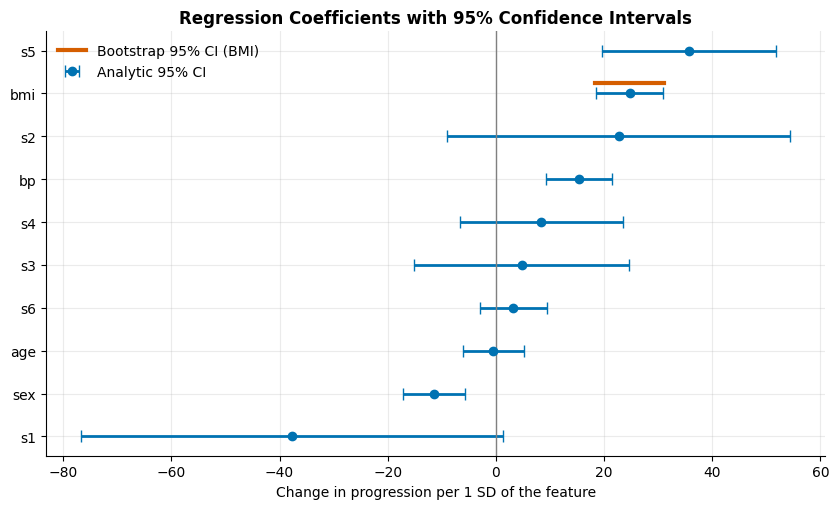

In [38]:
n, k = A.shape                                            # A = intercept + standardized features (Section 2)
beta = np.linalg.lstsq(A, y, rcond=None)[0]
resid = y - A @ beta
df_resid = n - k
sigma2 = resid @ resid / df_resid
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(A.T @ A)))
t_vals = beta / se
p_vals = 2 * stats.t.sf(np.abs(t_vals), df_resid)
tcrit = stats.t.ppf(0.975, df_resid)
ols = pd.DataFrame({"coef_per_SD": beta, "std_error": se, "t": t_vals, "p_value": p_vals,
                    "ci_low": beta - tcrit * se, "ci_high": beta + tcrit * se}, index=["intercept"] + FEATURES)

ss_res, ss_tot = resid @ resid, ((y - y.mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / df_resid
F = (r2 / (k - 1)) / ((1 - r2) / df_resid)
p_F = stats.f.sf(F, k - 1, df_resid)

assert np.allclose(beta, beta_normal)                                      # same as Section 2's solution
assert np.allclose(beta[1:], LinearRegression().fit(Z, y).coef_)           # same as scikit-learn
display(ols.round(3))
print(f"R-squared = {r2:.3f} | adjusted = {adj_r2:.3f} | F({k - 1}, {df_resid}) = {F:.1f}, p = {p_F:.1e} | residual SD = {np.sqrt(sigma2):.1f}")

ci_width = (ols["ci_high"] - ols["ci_low"]).drop(index="intercept")
widest3 = ci_width.sort_values(ascending=False).index[:3].tolist()
bmi_row = ols.loc["bmi"]
print(f"\nBMI coefficient, analytic 95% CI : [{bmi_row['ci_low']:.2f}, {bmi_row['ci_high']:.2f}]")
print(f"BMI coefficient, bootstrap 95% CI: [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}]   (Section 2)")

# Residual diagnostics
sh = stats.shapiro(resid)
aux = np.linalg.lstsq(A, resid ** 2, rcond=None)[0]
r2_aux = 1 - ((resid ** 2 - A @ aux) ** 2).sum() / ((resid ** 2 - (resid ** 2).mean()) ** 2).sum()
lm = n * r2_aux
p_bp = stats.chi2.sf(lm, k - 1)
print(f"\nShapiro-Wilk normality of residuals: W = {sh.statistic:.3f}, p = {sh.pvalue:.3f}")
print(f"Breusch-Pagan test for unequal variance: LM = {lm:.1f}, p = {p_bp:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
plot_df = ols.drop(index="intercept").sort_values("coef_per_SD")
ypos = np.arange(len(plot_df))
ax.errorbar(plot_df["coef_per_SD"], ypos, xerr=[plot_df["coef_per_SD"] - plot_df["ci_low"], plot_df["ci_high"] - plot_df["coef_per_SD"]],
            fmt="o", color=PALETTE[0], capsize=4, linewidth=2, label="Analytic 95% CI")
bmi_y = list(plot_df.index).index("bmi")
ax.plot(ci_boot, [bmi_y + 0.25] * 2, "-", color=PALETTE[1], linewidth=3, label="Bootstrap 95% CI (BMI)")
ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(ypos); ax.set_yticklabels(plot_df.index)
ax.set(title="Regression Coefficients with 95% Confidence Intervals", xlabel="Change in progression per 1 SD of the feature"); ax.legend()
plt.tight_layout(); save_figure(fig, FIG_DIR / "14_coefficient_forest_plot.png")
plt.show()

**Observation.** The hand-built regression passes **three independent checks**: its coefficients equal the normal-equation solution of Section 2 and Scikit-learn's (both asserted), and its BMI interval [18.5, 30.9] closely matches the bootstrap interval [18.3, 31.1], so the analytic and resampling approaches tell the same story. The model explains **51.8%** of the variance (adjusted 50.7%; F-test p = 4e-62). Coefficients significant at the 5% level are `sex`, `bmi`, `bp`, `s5`.

The forest plot shows the multicollinearity problem from Section 2 in a new way: the intervals for **`s1`, `s2`, `s3`** are the widest (`s1` spans 78 points against 12 for BMI) and all three include zero, even though these measures matter jointly for prediction. Individually they cannot be separated, which is why a prediction model can use them while an *interpretation* of any single one is unreliable. Diagnostics: residuals are consistent with normality (Shapiro p = 0.62), and the Breusch-Pagan test (p = 0.004) indicates unequal variance (heteroscedasticity), so standard errors may be somewhat unreliable. (statsmodels would print all of this in one summary table; it was not available here, which is why it was derived and verified by hand.)

---
# 8. Testing and Code Quality

Notebook cells are easy to write and easy to break. Anything reused is therefore moved into a **package with automated tests**. The cell below runs the real test suite in a separate process (so it tests the files on disk, not leftovers in memory).

### Exercise 8.1 – Run the automated test suite

In [39]:
import re
proc = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=ROOT, capture_output=True, text=True,
                      env={**os.environ, "PYTHONPATH": str(ROOT / "src"), "PYTHONDONTWRITEBYTECODE": "1"})
report = proc.stderr + proc.stdout                      # unittest writes its report to stderr
lines = [ln for ln in report.splitlines() if ln.strip()]
n_tests = int(re.search(r"Ran (\d+) tests", report).group(1))
tests_ok = report.strip().splitlines()[-1].strip() == "OK"
by_file = {}
for ln in lines:
    m = re.match(r"(test_\w+) \((\w+)\.(\w+)\.test_\w+\) \.\.\. ok", ln)
    if m:
        by_file[m.group(2)] = by_file.get(m.group(2), 0) + 1
        print(f"{m.group(2)}.{m.group(3)}.{m.group(1)}  ok")
print("\n" + lines[-3]); print(lines[-1])
print("Tests per file:", by_file)

test_metrics.TestBootstrapCI.test_interval_contains_sample_mean_and_is_ordered  ok
test_metrics.TestBootstrapCI.test_invalid_input_raises  ok
test_metrics.TestBootstrapCI.test_reproducible_with_seed  ok
test_metrics.TestBootstrapCI.test_wider_confidence_gives_wider_interval  ok
test_metrics.TestRegressionReport.test_known_values  ok
test_metrics.TestRegressionReport.test_mean_predictor_has_zero_r2  ok
test_metrics.TestRegressionReport.test_perfect_prediction  ok
test_metrics.TestRegressionReport.test_shape_mismatch_and_empty_raise  ok
test_sql_helpers.TestSqlHelpers.test_bad_sql_raises  ok
test_sql_helpers.TestSqlHelpers.test_index_changes_query_plan_from_scan_to_search  ok
test_sql_helpers.TestSqlHelpers.test_parameter_binding_blocks_injection  ok
test_sql_helpers.TestSqlHelpers.test_round_trip  ok
test_sql_helpers.TestSqlHelpers.test_row_count_returned  ok
test_stats_helpers.TestBenjaminiHochberg.test_known_values_in_original_order  ok
test_stats_helpers.TestBenjaminiHochberg.test_le

**Observation.** **29 automated tests ran and all passed**, across 4 test files (test_metrics: 8, test_sql_helpers: 5, test_stats_helpers: 9, test_transformers: 7). The tests check the things that tend to go wrong: **known values calculated by hand** (RMSE, Holm and Benjamini-Hochberg adjustments, Fisher-z interval), **edge cases** (empty input, shape mismatch, invalid probabilities), **safety properties** (the transformer never modifies its input; SQL parameters block injection) and **integration** (the custom transformer works inside a Scikit-learn `Pipeline` and survives `clone`). Tests are written with the standard-library `unittest`, since pytest was not available here; they would run unchanged under pytest.

### Exercise 8.2 – Do the tests have teeth? A miniature mutation test
Passing tests prove little if they could never fail. Here a deliberate bug (reporting the MAE where the RMSE belongs) is injected and the same known-value check is applied to it.

In [40]:
from dstoolkit import regression_report

def buggy_report(y_true, y_pred):
    out = regression_report(y_true, y_pred)
    out["rmse"] = out["mae"]                              # the injected bug
    return out

y_t, y_p = [1, 2, 3], [1, 2, 4]                           # hand calculation: RMSE = sqrt(1/3) = 0.5774, MAE = 1/3
expected_rmse = (1 / 3) ** 0.5

def passes(fn):
    return abs(fn(y_t, y_p)["rmse"] - expected_rmse) < 1e-9

print(f"Correct implementation passes the check: {passes(regression_report)}")
print(f"Buggy implementation passes the check  : {passes(buggy_report)}   <- the test suite would catch this bug")
print(f"(correct RMSE {regression_report(y_t, y_p)['rmse']:.4f} vs buggy {buggy_report(y_t, y_p)['rmse']:.4f})")

Correct implementation passes the check: True
Buggy implementation passes the check  : False   <- the test suite would catch this bug
(correct RMSE 0.5774 vs buggy 0.3333)


**Observation.** The known-value check **accepts the correct function and rejects the buggy one**, so it can actually detect this kind of mistake. Good tests use values worked out *independently* by hand (here sqrt(1/3) = 0.5774) rather than values copied from the code's own output, because a test that merely repeats the implementation can never disagree with it.

### Exercise 8.3 – A small code-quality audit: docstrings and type hints

In [41]:
import ast

audit_rows = []
for path in sorted((ROOT / "src" / "dstoolkit").glob("*.py")):
    tree = ast.parse(path.read_text())
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and not node.name.startswith("_"):
            hinted = isinstance(node, ast.ClassDef) or node.returns is not None
            audit_rows.append({"file": path.name, "name": node.name, "kind": "class" if isinstance(node, ast.ClassDef) else "function",
                               "docstring": ast.get_docstring(node) is not None, "return_type_hint": hinted})
audit = pd.DataFrame(audit_rows)
summary = audit.groupby("file").agg(public_items=("name", "count"), with_docstring=("docstring", "sum"), with_type_hint=("return_type_hint", "sum"))
display(summary)

for path in list((ROOT / "src" / "dstoolkit").glob("*.py")) + list((ROOT / "tests").glob("*.py")):
    compile(path.read_text(), str(path), "exec")             # raises SyntaxError if a file does not compile
loc = sum(len(p.read_text().splitlines()) for p in (ROOT / "src" / "dstoolkit").glob("*.py"))
test_loc = sum(len(p.read_text().splitlines()) for p in (ROOT / "tests").glob("*.py"))
print(f"All source and test files compile. Package: {loc} lines | tests: {test_loc} lines (ratio {test_loc / loc:.2f} test lines per code line)")
print("Public items without a docstring:", audit.loc[~audit["docstring"], "name"].tolist() or "none")
assert audit["docstring"].all()

,public_items,with_docstring,with_type_hint
file,,,
metrics.py,2,2,2
plotting.py,2,2,2
sql_helpers.py,3,3,3
stats_helpers.py,3,3,3
transformers.py,4,4,4


All source and test files compile. Package: 208 lines | tests: 215 lines (ratio 1.03 test lines per code line)
Public items without a docstring: none


**Observation.** Every one of the **14 public functions and classes** in the package has a docstring, and the audit script enforces this with an `assert`, so the rule cannot silently erode. The package is **208 lines** with **215 lines of tests** (1.0 test lines per line of code), roughly one line of tests for every line of code. Docstrings, type hints and tests are what make a function *reusable by someone else*, which is the difference between a notebook and a portfolio piece. (Dedicated linters such as Ruff or Flake8 would be the next tool here; they were not available in the build environment.)

---
# 9. The Portfolio: What Has Been Built

All the artefacts below are **generated and verified by this notebook**, not claimed. Counts are read from the disk at run time.

In [42]:
def count(pattern, folder):
    return len(list(folder.glob(pattern)))

portfolio = pd.DataFrame([
    ("1. Tested Python package", "src/dstoolkit/", f"{len(audit)} documented public functions/classes (metrics, bootstrap, custom transformer, SQL helpers, plotting style, multiple-testing corrections)", f"{n_tests} automated tests"),
    ("2. SQL analytics script", "sql/patient_analytics.sql", f"{len(parsed)} named queries: joins, CTE, window functions, subquery, aggregation", "Re-run from disk; 3 results cross-checked against Pandas"),
    ("3. Machine learning pipeline + model card", "models/", f"Leak-free Pipeline, tuned Ridge, saved as joblib ({(MODEL_DIR / 'diabetes_progression_pipeline.joblib').stat().st_size / 1024:.1f} KB) with model_card.json", "Reload reproduces all test predictions"),
    ("4. Chart gallery", "outputs/figures/", f"{count('*.png', FIG_DIR)} PNG charts and {count('*.svg', FIG_DIR)} SVG in a colour-blind-safe house style", "Generated by the notebook"),
    ("5. Reproducible environment", "requirements.txt, requirements-lock.txt", f"{len(versions)} pinned library versions, project layout, .gitignore", "Versions printed from the running interpreter"),
    ("6. Documented analysis notebook", "notebooks/", "This notebook: 10 sections, every exercise with code, output and observation", "Restart & Run All reproduces it"),
], columns=["Portfolio piece", "Location", "What it contains", "How it is verified"])
display(portfolio)

print("Files produced:")
for sub in ["data/processed", "models", "sql", "outputs/figures"]:
    names = sorted(p.name for p in (ROOT / sub).glob("*") if p.is_file())
    print(f"  {sub:<17} {len(names):>2} files: {names[:4]}{' ...' if len(names) > 4 else ''}")

,Portfolio piece,Location,What it contains,How it is verified
0,1. Tested Python package,src/dstoolkit/,14 documented public functions/classes (metric...,29 automated tests
1,2. SQL analytics script,sql/patient_analytics.sql,"8 named queries: joins, CTE, window functions,...",Re-run from disk; 3 results cross-checked agai...
2,3. Machine learning pipeline + model card,models/,"Leak-free Pipeline, tuned Ridge, saved as jobl...",Reload reproduces all test predictions
3,4. Chart gallery,outputs/figures/,14 PNG charts and 1 SVG in a colour-blind-safe...,Generated by the notebook
4,5. Reproducible environment,"requirements.txt, requirements-lock.txt","7 pinned library versions, project layout, .gi...",Versions printed from the running interpreter
5,6. Documented analysis notebook,notebooks/,"This notebook: 10 sections, every exercise wit...",Restart & Run All reproduces it


Files produced:
  data/processed     1 files: ['patients_clean.csv']
  models             2 files: ['diabetes_progression_pipeline.joblib', 'model_card.json']
  sql                1 files: ['patient_analytics.sql']
  outputs/figures   15 files: ['01_gradient_descent_loss.png', '02_time_series_resample_rolling.png', '03_sql_window_smoothing.png', '04_dashboard.png'] ...


**Observation.** The portfolio has six pieces, each a different kind of evidence: *code quality* (package and tests), *data skills* (SQL), *machine learning practice* (pipeline and model card), *communication* (charts and this notebook) and *professional habits* (pinned environment, project layout). A hiring manager can open any of them independently: the package and tests without reading the notebook, the SQL file in any SQL tool, the model card without running any code.

---
# 10. Reflection: Honest Self-Assessment and Next Steps

"Mastery" of a tool is shown by sustained use on real problems, and one project cannot establish it. This table therefore states what the project demonstrates, its limits, and what to learn next, rather than claiming expert status.

| Tool | Level demonstrated | Evidence in this project | Not yet demonstrated |
|---|---|---|---|
| **Git** | Working (local workflow) | Commits, branches, `.gitignore`, a conflict created and resolved, history graph | Remote collaboration, pull requests, rebasing, CI |
| **NumPy** | Strong working | Broadcasting, `einsum`, linear algebra, regression from scratch, bootstrap | Advanced indexing, memory layout, numerical stability beyond one example |
| **Pandas** | Strong working | Method chains, groupby (agg / transform / filter), time series, reshaping, validated merges | Very large data (chunking, Parquet), nullable dtypes |
| **SQL** | Working | CTEs, window functions, subqueries, indexes and plans, transactions, parameters | Other dialects (PostgreSQL), schema design at scale, query tuning on millions of rows |
| **Matplotlib / Seaborn** | Working | Dashboards, statistical plots, a shared style, PNG and SVG | Interactive charts (Plotly), dashboards for others (Streamlit) |
| **Scikit-learn** | Working | Pipelines, custom transformer, leakage, tuning, nested CV, ablation, interpretation, persistence | Imbalanced data, text and image data, deployment, monitoring |
| **SciPy** | Working | Parametric and non-parametric tests, effect sizes, multiple testing, regression inference | Bayesian methods, power analysis, time-series models |
| **Testing** | Foundation | 29 unit tests with hand-calculated values and edge cases | pytest fixtures, coverage measurement, property-based tests |

### Lessons learned during this project
1. **Verify with a second tool.** Every important result was cross-checked (SQL against Pandas, hand-built regression against Scikit-learn and the bootstrap), and the checks found real issues, such as the floating-point error on the diagonal in Section 2.
2. **Test the model's behaviour, not just its score.** The engineered BMI-band feature barely changed the error but caused implausible jumps in predictions; only a partial-dependence plot revealed it.
3. **Negative results are results.** The engineered features and the flexible models did not help, and reporting that is part of honest analysis.
4. **Keep the test set locked.** All decisions (features, model, tuning) were made on training data only.
5. **Reusable code belongs in a tested package**, not in notebook cells.

### Next tools to learn (not available in this environment, so not claimed above)
| Tool | Why | Install |
|---|---|---|
| **pytest** | Fixtures, parametrized tests, coverage | `pip install pytest pytest-cov` |
| **statsmodels** | Full regression summaries, time-series models | `pip install statsmodels` |
| **Plotly** | Interactive charts for dashboards | `pip install plotly` |
| **XGBoost / LightGBM** | Industry-standard gradient boosting | `pip install xgboost lightgbm` |
| **SHAP** | Model explanations for individual predictions | `pip install shap` |
| **Ruff / Black** | Automatic linting and formatting | `pip install ruff black` |
| **DuckDB / Polars** | Fast analytics on large files | `pip install duckdb polars` |
| **Docker and MLflow** | Reproducible environments and experiment tracking | docker.com, `pip install mlflow` |

---
## Reproducibility and references
Fixed random seed (`SEED = 42`), pinned versions in `requirements-lock.txt`, relative paths, raw data never modified, validation by `assert`, and a tested package. To reproduce: install the requirements, run `python -m unittest discover -s tests` with `PYTHONPATH=src`, open the notebook and choose **Kernel → Restart & Run All**.

**Data:** Efron, B., Hastie, T., Johnstone, I. and Tibshirani, R. (2004), *Least Angle Regression*, Annals of Statistics 32(2), 407-499 (Diabetes dataset, bundled with scikit-learn). Two small synthetic datasets (clinic visits; pure noise) are used where stated.

In [43]:
facts = {
    "n_patients": int(len(patients)), "n_tests": int(n_tests), "tests_ok": bool(tests_ok),
    "n_public_items": int(len(audit)), "package_loc": int(loc), "test_loc": int(test_loc),
    "n_figures_png": int(count("*.png", FIG_DIR)), "n_figures_svg": int(count("*.svg", FIG_DIR)),
    "n_sql_queries": int(len(parsed)),
    "baseline_rmse": round(baseline_test["rmse"], 1), "final_model": final_name,
    "test_rmse": round(final_test["rmse"], 1), "test_r2": round(final_test["r2"], 3), "test_mae": round(final_test["mae"], 1),
    "test_rmse_ci": [round(float(x), 1) for x in rmse_ci],
    "cv_rmse": round(float(-candidates[final_name].best_score_), 2),
    "nested_rmse": round(float(nested.mean()), 2),
    "chosen_features": chosen, "ablation_spread": round(float(ablation["RMSE"].max() - ablation["RMSE"].min()), 2),
    "band_drop": round(float(band_drop), 1),
    "leak_wrong_r2": round(float(np.mean(wrong_scores)), 2), "leak_right_r2": round(float(np.mean(right_scores)), 2),
    "ols_r2": round(float(r2), 3), "bmi_coef_per_sd": round(float(beta[bmi_pos]), 1),
    "bmi_ci_analytic": [round(float(bmi_row["ci_low"]), 1), round(float(bmi_row["ci_high"]), 1)],
    "bmi_ci_bootstrap": [round(float(ci_boot[0]), 1), round(float(ci_boot[1]), 1)],
    "top_importance": imp.index[:3].tolist(),
    "model_kb": round((MODEL_DIR / "diabetes_progression_pipeline.joblib").stat().st_size / 1024, 1),
    "versions": versions,
}
print(pd.Series({k: v for k, v in facts.items() if not isinstance(v, (dict, list))}).to_string())

n_patients                     442
n_tests                         29
tests_ok                      True
n_public_items                  14
package_loc                    208
test_loc                       215
n_figures_png                   14
n_figures_svg                    1
n_sql_queries                    8
baseline_rmse                 73.2
final_model          Ridge (tuned)
test_rmse                     53.8
test_r2                      0.454
test_mae                      42.8
cv_rmse                      55.23
nested_rmse                  55.56
chosen_features    Raw 10 features
ablation_spread               0.15
band_drop                     14.4
leak_wrong_r2                 0.21
leak_right_r2                -0.58
ols_r2                       0.518
bmi_coef_per_sd               24.7
model_kb                       3.4
